In [136]:
# command to reload libraries
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [137]:
from desReg.des.DESRegression import DESRegression
from desReg.utils import measures as em
from run_experiments import run_experiment_with_timeout, get_df_results, get_agg_results

import numpy as np
import pandas as pd
import datetime as dt
import seaborn as sns
import pickle
from matplotlib import pyplot as plt

pd.set_option('display.max_columns', None)

In [138]:
def save_pickle(obj, filename):
    with open(f"artifacts/{filename}", "wb") as file:
        pickle.dump(obj, file)
        print(f"Saved into artifacts/{filename}")

def load_pickle(filename):
    with open(f"artifacts/{filename}", "rb") as file:
        obj = pickle.load(file)
    return obj

## Calculate Instance Hardness for Test Set

In [4]:
from run_experiments import partitions_dict

train_df_dict= {}
datasets = {}
for partition_alias, partition_name in partitions_dict.items():
    n_fold = 5
    train_df = pd.DataFrame()
    test_df = pd.DataFrame()
    for p in range(1,n_fold+1):
        name_train = partition_name+str(p)+'tra.dat'
        name_test = partition_name+str(p)+'tst.dat'

        data_train = pd.read_csv(name_train,header = None)
        columns = [f"V{i}" for i in range(data_train.shape[1] - 1)]
        columns.append("y")
        data_train.columns = columns
        X_train = data_train.iloc[:,:-1].to_numpy()
        y_train = np.ravel(data_train.iloc[:, -1:])

        data_test = pd.read_csv(name_test, header=None)
        data_test.columns = columns
        X_test = data_test.iloc[:,:-1].to_numpy()
        y_test = np.ravel(data_test.iloc[:, -1:])

        train_df = pd.concat([train_df, data_train], ignore_index=True)
        test_df = pd.concat([test_df, data_test], ignore_index=True)

    datasets[partition_alias] = dict(
        train_df = train_df,
        test_df = test_df
    )

In [5]:
from desReg.utils import instance_hardness as ih

all_meta_features_test_dict = {}
for name, data in datasets.items():
    # if name in ["yacht"]:
    all_meta_features_test_dict[name] = dict()
    X_test = data['test_df'].drop(columns=['y'])
    y_test = data['test_df'][['y']]
    instance_hardness_df = ih.get_instance_hardness(X_test, y_test)
    all_hardness_measures = ih.get_hardness_measures(X_test, y_test)
    all_meta_features_test_dict[name]['instance_hardness'] = instance_hardness_df
    all_meta_features_test_dict[name]['hardness_measures'] = all_hardness_measures

In [6]:
consolidated_meta_features_test = dict()
for name in all_meta_features_test_dict.keys():
    consolidated_meta_features_test[name] = ih.consolidate_data(
        all_meta_features_test_dict[name]['instance_hardness'], 
        all_meta_features_test_dict[name]['hardness_measures']
    )

In [7]:
consolidated_meta_features_test['abalone']

,V0,V1,V2,V3,V4,V5,V6,V7,y,algo_ada_boost,algo_svr_linear,algo_svr_epsilon,algo_svr_nu,algo_decision_tree,algo_random_forest,algo_extra_tree,algo_gradient_boosting,algo_mlp,algo_bagging,algo_bayesian_ard,algo_kernel_ridge,algo_sgd,algo_passive_aggressive,algo_dummy_regressor,instance_hardness,inverse_instance_hardness,normalized_instance_hardness,normalized_inverse_instance_hardness,V0,V1,V2,V3,V4,V5,V6,V7,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U,inverse_C4,inverse_L1,inverse_S1,inverse_S2,inverse_S3,inverse_FO,inverse_POT,inverse_HB,inverse_EDS,inverse_EZR,inverse_DS,inverse_TD_P,inverse_TD_U,inverse_D,inverse_CC
0,2,0.495,0.380,0.120,0.5730,0.2655,0.1285,0.1440,7,2.826271,1.342357,1.334835,1.642761,1.0,0.82,1.08,1.649433,1.205626,0.9,1.644805,8.319529,1.660698,2.156131,2.961999,0.175763,0.824237,0.219896,0.891444,2,0.495,0.380,0.120,0.5730,0.2655,0.1285,0.1440,7,1.000000,0.999300,0.446360,0.159048,0.017801,0.145943,0.000,0.906392,0.339855,0,0.007373,0.563621,0.106201,0.428571,0.392857,0.000000,0.660145,0.992627,0.436379,0.893799,1.000,1,0.093608,0.982199,0.854057,0.840952,0.571429,0.607143,0.553640,0.000700
1,3,0.250,0.190,0.060,0.0765,0.0360,0.0115,0.0245,6,0.484848,0.622333,0.574288,0.919483,2.0,0.96,1.14,0.921676,0.925162,1.3,0.240757,10.077785,0.064813,2.432313,3.856929,0.139372,0.860628,0.174368,0.930802,3,0.250,0.190,0.060,0.0765,0.0360,0.0115,0.0245,6,0.333333,0.999655,0.775144,0.888571,0.131113,0.298794,0.000,0.937994,0.061819,0,0.001754,0.703311,0.106201,0.428571,0.464286,0.666667,0.938181,0.998246,0.296689,0.893799,1.000,1,0.062006,0.868887,0.701206,0.111429,0.571429,0.535714,0.224856,0.000345
2,3,0.165,0.120,0.030,0.0215,0.0070,0.0050,0.0050,3,2.666667,1.183850,1.188188,1.091695,2.0,1.26,1.67,1.260553,0.993998,1.4,1.380166,8.540350,1.457002,7.858836,6.936845,0.217471,0.782529,0.272077,0.846335,3,0.165,0.120,0.030,0.0215,0.0070,0.0050,0.0050,3,1.000000,0.999681,0.844349,0.888571,0.700155,0.758241,0.375,0.996409,0.340543,1,0.002512,0.713380,0.075007,0.428571,0.250000,0.000000,0.659457,0.997488,0.286620,0.924993,0.625,0,0.003591,0.299845,0.241759,0.111429,0.571429,0.750000,0.155651,0.000319
3,1,0.575,0.450,0.155,0.9480,0.4290,0.2060,0.2590,7,5.062827,3.239580,3.247611,2.914639,12.0,4.99,4.38,2.986757,2.577352,4.0,3.537535,6.416449,3.496116,4.289242,2.961999,0.347292,0.652708,0.434496,0.705928,1,0.575,0.450,0.155,0.9480,0.4290,0.2060,0.2590,7,1.000000,0.999344,0.483238,0.000000,0.634882,0.145943,0.000,0.906392,0.523323,0,0.007648,0.777913,0.267927,0.857143,0.500000,0.000000,0.476677,0.992352,0.222087,0.732073,1.000,1,0.093608,0.365118,0.854057,1.000000,0.142857,0.500000,0.516762,0.000656
4,2,0.535,0.415,0.170,0.8790,0.2950,0.1965,0.2850,10,5.212740,1.515761,1.540969,2.702919,6.0,3.54,3.74,3.247283,3.738464,3.4,2.155610,7.718831,1.955335,1.835413,0.143071,0.258730,0.741270,0.323696,0.801711,2,0.535,0.415,0.170,0.8790,0.2950,0.1965,0.2850,10,0.777778,0.999178,0.402538,0.548571,0.076006,0.038672,0.000,0.848216,0.418931,0,0.012120,0.731698,0.593966,0.857143,0.607143,0.222222,0.581069,0.987880,0.268302,0.406034,1.000,1,0.151784,0.923994,0.961328,0.451429,0.142857,0.392857,0.597462,0.000822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4172,2,0.460,0.360,0.115,0.4755,0.2105,0.1050,0.1600,8,3.018492,0.549390,0.558331,1.559938,1.0,2.05,1.98,2.271156,1.290917,1.8,0.955971,8.885066,1.173705,1.705792,1.856929,0.168497,0.831503,0.210806,0.899302,2,0.460,0.360,0.115,0.4755,0.2105,0.1050,0.1600,8,1.000000,0.999377,0.481082,0.159048,0.011351,0.038672,0.000,0.864017,0.235422,0,0.004342,0.587568,0.314336,0.428571,0.428571,0.000000,0.764578,0.995658,0.412432,0.685664,1.000,1,0.135983,0.988649,0.961328,0.840952,0.571429,0.571429,0.518918,0.000623
4173,1,0.535,0.420,0.145,0.7910,0.3300,0.1890,0.2500,10,3

## Abalone

### DES Ensembles

In [8]:
from ensemble_versions import des_challenger_experiments, des_baseline_ensemble

des_abalone_results = run_experiment_with_timeout(
    'abalone', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

========== Processing abalone - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [10]:
# Serialize results
save_pickle(des_abalone_results, "des_abalone_results.pkl")

Saved into artifacts/des_abalone_results.pkl


In [139]:
des_abalone_results = load_pickle("des_abalone_results.pkl")
des_abalone_results_df = get_df_results(des_abalone_results)
des_abalone_agg_results = get_agg_results(des_abalone_results_df)
des_abalone_agg_results

mse          \
                            mean     std   
model_name                                 
baseline                  4.7229  0.4447   
des_ensemble_d            4.7044  0.3892   
des_ensemble_eds          4.7561  0.5100   
des_ensemble_ezr          4.7420  0.3832   
des_ensemble_ih           4.7226  0.4130   
des_ensemble_inverse_d    4.6994  0.4222   
des_ensemble_inverse_eds  4.6840  0.3764   
des_ensemble_inverse_ezr  4.7001  0.4013   
des_ensemble_inverse_ih   4.6896  0.3889   
des_ensemble_inverse_l1   4.6844  0.3755   
des_ensemble_inverse_s1   4.6857  0.4029   
des_ensemble_inverse_s2   4.6828  0.4027   
des_ensemble_inverse_s3   4.6919  0.3666   
des_ensemble_l1           4.7390  0.4037   
des_ensemble_s1           4.6811  0.4423   
des_ensemble_s2           4.6967  0.4049   
des_ensemble_s3           4.7812  0.4683   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'KNeighborsRegressor': 58942, 'DecisionTreeRe...   
des_ensemble_d            {'KNeighborsRegressor': 52220, 'DecisionTreeRe...   
des_ensemble_eds          {'Ridge': 37718, 'KNeighborsRegressor': 51996,...   
des_ensemble_ezr          {'Ridge': 38477, 'KNeighborsRegressor': 52204,...   
des_ensemble_ih           {'KNeighborsRegressor': 52355, 'DecisionTreeRe...   
des_ensemble_inverse_d    {'Ridge': 33614, 'KNeighborsRegressor': 52605,...   
des_ensemble_inverse_eds  {'KNeighborsRegressor': 52419, 'DecisionTreeRe...   
des_ensemble_inverse_ezr  {'KNeighborsRegressor': 52244, 'DecisionTreeRe...   
des_ensemble_inverse_ih   {'KNeighborsRegressor': 52403, 'DecisionTreeRe...   
des_ensemble_inverse_l1   {'KNeighborsRegressor': 52326, 'DecisionTreeRe...   
des_ensemble_inverse_s1   {'KNeighborsRegressor': 52408, 'DecisionTreeRe...   
des_ensemble_inverse_s2   {'KNeighborsRegressor': 52561, 'DecisionTreeRe...   
des_ensemble_inverse_s3   {'KNeighborsRegressor': 52389, 'DecisionTreeRe...   
des_ensemble_l1           {'KNeighborsRegressor': 52344, 'DecisionTreeRe...   
des_ensemble_s1           {'KNeighborsRegressor': 52335, 'DecisionTreeRe...   
des_ensemble_s2           {'KNeighborsRegressor': 52349, 'DecisionTreeRe...   
des_ensemble_s3           {'Ridge': 37393, 'KNeighborsRegressor': 51979,...   

                         execution_time                             algo_name  \
                                   mean     std       sum KNeighborsRegressor   
model_name                                                                      
baseline                        61.1295  2.9521  305.6477               58942   
des_ensemble_d                  55.7075  1.0673  278.5373               52220   
des_ensemble_eds                56.1588  0.9030  280.7941               51996   
des_ensemble_ezr                55.7607  0.9946  278.8036               52204   
des_ensemble_ih                 72.3923  9.7303  361.9614               52355   
des_ensemble_inverse_d          56.0195  0.7819  280.0973               52605   
des_ensemble_inverse_eds        56.1271  0.9965  280.6353               52419   
des_ensemble_inverse_ezr        55.7560  0.8776  278.7801               52244   
des_ensemble_inverse_ih         71.3686  7.1466  356.8432               52403   
des_ensemble_inverse_l1         56.3096  0.7647  281.5480               52326   
des_ensemble_inverse_s1         63.0796  7.9296  315.3982               52408   
des_ensemble_inverse_s2         56.0765  1.0234  280.3827               52561   
des_ensemble_inverse_s3         55.9053  0.9705  279.5263               52389   
des_ensemble_l1                 56.3970  0.7098  281.9849               52344   
des_ensemble_s1                 60.0580  0.7911  300.2902               52335   
des_ensemble_s2                 56.7316  1.6143  283.6582               52349   
des_ensemble_s3             

### DRS Ensemble

In [12]:
from ensemble_versions import drs_challenger_experiments, drs_baseline_ensemble

drs_abalone_results = run_experiment_with_timeout(
    'abalone', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)


========== Processing abalone - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [13]:
save_pickle(drs_abalone_results, "drs_abalone_results.pkl")

Saved into artifacts/drs_abalone_results.pkl


In [9]:
def concatenate_y_pred(drs_results):
    for partition, partition_results in drs_results.items():
        # Iterate through each model in the dictionary
        for model_name, metrics in partition_results.items():
            if isinstance(metrics['y_pred'][0], np.ndarray):
                drs_results[partition][model_name]['y_pred'] = np.concatenate(metrics['y_pred']).tolist()
    return drs_results

In [10]:
drs_abalone_results = load_pickle('drs_abalone_results.pkl')
drs_abalone_results = concatenate_y_pred(drs_abalone_results)
drs_abalone_results_df = get_df_results(drs_abalone_results)
drs_abalone_agg_results = get_agg_results(drs_abalone_results_df)
drs_abalone_agg_results

mse         ensemble_sizes      execution_time            \
                    mean     std           mean  std           mean       std   
model_name                                                                      
baseline          5.7580  0.3684            1.0  0.0       246.6903  428.1840   
drs_ensemble_d    9.2987  0.7308            1.0  0.0       254.3934  454.8691   
drs_ensemble_eds  9.1994  0.8281            1.0  0.0       251.2816  447.1360   
drs_ensemble_ezr  9.1697  0.7180            1.0  0.0       234.6727  410.0707   
drs_ensemble_ih   9.2903  0.7769            1.0  0.0        66.8749    5.3248   
drs_ensemble_l1   9.3001  0.7893            1.0  0.0       242.9379  428.1744   
drs_ensemble_s1   9.3200  0.8104            1.0  0.0       258.1234  454.4012   
drs_ensemble_s2   9.4304  0.8385            1.0  0.0       248.2073  438.1362   
drs_ensemble_s3   9.3474  0.8631            1.0  0.0       433.5635  854.7497   

                             
                        sum  
model_name                   
baseline          1233.4517  
drs_ensemble_d    1271.9672  
drs_ensemble_eds  1256.4081  
drs_ensemble_ezr  1173.3635  
drs_ensemble_ih    334.3743  
drs_ensemble_l1   1214.6895  
drs_ensemble_s1   1290.6171  
drs_ensemble_s2   1241.0363  
drs_ensemble_s3   2167.8175

### SE Ensembles

In [16]:
from ensemble_versions import se_challenger_experiments, se_baseline_ensemble

se_abalone_results = run_experiment_with_timeout(
    'abalone', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)
se_abalone_results_df = get_df_results(se_abalone_results)
se_abalone_agg_results = get_agg_results(se_abalone_results_df)
se_abalone_agg_results


========== Processing abalone - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing abalone - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing abalone - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


... (2 outputs left out)

Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing abalone - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...


mse         ensemble_sizes      execution_time  \
                        mean     std           mean  std           mean   
model_name                                                                
baseline              4.9603  0.4863          100.0  0.0         1.1825   
se_baseline_ensemble  4.9603  0.4863          100.0  0.0         1.1864   
se_ensemble_ih        4.9603  0.4863          100.0  0.0        16.1991   

                                       
                         std      sum  
model_name                             
baseline              0.0596   5.9124  
se_baseline_ensemble  0.0390   5.9318  
se_ensemble_ih        0.7790  80.9953

## Student Marks

### DES Ensembles

In [32]:
from ensemble_versions import des_challenger_experiments, des_baseline_ensemble, des_inverse_challenger_experiments

des_student_marks_results = run_experiment_with_timeout(
    'student_marks', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_student_marks_results = run_experiment_with_timeout(
#     'student_marks', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )

========== Processing student_marks - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [33]:
save_pickle(des_student_marks_results, "des_student_marks_results.pkl")

Saved into artifacts/des_student_marks_results.pkl


In [44]:
des_student_marks_results = load_pickle("des_student_marks_results.pkl")
des_student_marks_results_df = get_df_results(des_student_marks_results)
des_student_marks_agg_results = get_agg_results(des_student_marks_results_df)
des_student_marks_agg_results

mse          \
                            mean     std   
model_name                                 
baseline                  2.3476  1.5707   
des_ensemble_d            1.7898  1.3612   
des_ensemble_eds          1.9702  1.3241   
des_ensemble_ezr          2.0112  1.5641   
des_ensemble_ih           1.8145  1.3861   
des_ensemble_inverse_d    1.8278  1.3586   
des_ensemble_inverse_eds  1.8555  1.3104   
des_ensemble_inverse_ezr  1.8274  1.2950   
des_ensemble_inverse_ih   1.7851  1.3507   
des_ensemble_inverse_l1   1.7900  1.3536   
des_ensemble_inverse_s1   1.7981  1.3513   
des_ensemble_inverse_s2   1.7905  1.3764   
des_ensemble_inverse_s3   1.8288  1.3194   
des_ensemble_l1           1.8284  1.3541   
des_ensemble_s1           1.8526  1.3874   
des_ensemble_s2           1.7737  1.3172   
des_ensemble_s3           2.1125  1.5258   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Lasso': 655, 'Ridge': 683, 'KNeighborsRegres...   
des_ensemble_d            {'Lasso': 498, 'Ridge': 634, 'KNeighborsRegres...   
des_ensemble_eds          {'Lasso': 594, 'Ridge': 720, 'KNeighborsRegres...   
des_ensemble_ezr          {'Lasso': 593, 'Ridge': 757, 'KNeighborsRegres...   
des_ensemble_ih           {'Lasso': 512, 'Ridge': 651, 'KNeighborsRegres...   
des_ensemble_inverse_d    {'Lasso': 492, 'Ridge': 616, 'KNeighborsRegres...   
des_ensemble_inverse_eds  {'Lasso': 465, 'Ridge': 577, 'KNeighborsRegres...   
des_ensemble_inverse_ezr  {'Lasso': 470, 'Ridge': 597, 'KNeighborsRegres...   
des_ensemble_inverse_ih   {'Lasso': 491, 'Ridge': 630, 'KNeighborsRegres...   
des_ensemble_inverse_l1   {'Lasso': 491, 'Ridge': 625, 'KNeighborsRegres...   
des_ensemble_inverse_s1   {'Lasso': 494, 'Ridge': 631, 'KNeighborsRegres...   
des_ensemble_inverse_s2   {'Lasso': 515, 'Ridge': 636, 'KNeighborsRegres...   
des_ensemble_inverse_s3   {'Lasso': 492, 'Ridge': 596, 'KNeighborsRegres...   
des_ensemble_l1           {'Lasso': 522, 'Ridge': 649, 'KNeighborsRegres...   
des_ensemble_s1           {'Lasso': 522, 'Ridge': 668, 'KNeighborsRegres...   
des_ensemble_s2           {'Lasso': 471, 'Ridge': 626, 'KNeighborsRegres...   
des_ensemble_s3           {'Lasso': 604, 'Ridge': 795, 'KNeighborsRegres...   

                         execution_time                  algo_name        \
                                   mean     std      sum     Lasso Ridge   
model_name                                                                 
baseline                         2.1182  2.5528  10.5911       655   683   
des_ensemble_d                   1.3380  0.6244   6.6900       498   634   
des_ensemble_eds                 1.0833  0.2006   5.4165       594   720   
des_ensemble_ezr                 1.1076  0.3085   5.5382       593   757   
des_ensemble_ih                  1.7058  0.0775   8.5290       512   651   
des_ensemble_inverse_d           1.3581  0.5813   6.7907       492   616   
des_ensemble_inverse_eds         1.0515  0.2018   5.2573       465   577   
des_ensemble_inverse_ezr         1.0974  0.1909   5.4868       470   597   
des_ensemble_inverse_ih          1.7521  0.1400   8.7607       491   630   
des_ensemble_inverse_l1          1.0558  0.1637   5.2792       491   625   
des_ensemble_inverse_s1          0.9931  0.0503   4.9653       494   631   
des_ensemble_inverse_s2          0.9909  0.0499   4.9545       515   636   
des_ensemble_inverse_s3          1.0016  0.0699   5.0079       492   596   
des_ensemble_l1                  1.1990  0.3118   5.9952       522   649   
des_ensemble_s1                  1.0179  0.0966   5.0896       522   668   
des_ensemble_s2                  0.9923  0.0384   4.9617       471   626   
des_ensemble_s3                  0.9831  0.0544   4.9154       604   795   

                                              

In [10]:
len(des_student_marks_results[5]['baseline']['y_pred'])

20

### DRS Ensemble

In [20]:
from ensemble_versions import drs_challenger_experiments, drs_baseline_ensemble

drs_student_marks_results = run_experiment_with_timeout(
    'student_marks', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)

========== Processing student_marks - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [21]:
save_pickle(drs_student_marks_results, "drs_student_marks_results.pkl")

Saved into artifacts/drs_student_marks_results.pkl


In [22]:
drs_student_marks_results = load_pickle("drs_student_marks_results.pkl")
drs_student_marks_results = concatenate_y_pred(drs_student_marks_results)
drs_student_marks_results_df = get_df_results(drs_student_marks_results)
drs_student_marks_agg_results = get_agg_results(drs_student_marks_results_df)
drs_student_marks_agg_results

mse         ensemble_sizes      execution_time          \
                    mean     std           mean  std           mean     std   
model_name                                                                    
baseline          3.9444  4.3089            1.0  0.0         0.8539  0.0179   
drs_ensemble_d    4.5125  1.5674            1.0  0.0         0.8632  0.0119   
drs_ensemble_eds  4.3445  1.6968            1.0  0.0         0.8633  0.0185   
drs_ensemble_ezr  4.6648  1.5865            1.0  0.0         0.8621  0.0077   
drs_ensemble_ih   4.5125  1.5674            1.0  0.0         1.5222  0.0073   
drs_ensemble_l1   4.3205  1.7526            1.0  0.0         0.8593  0.0073   
drs_ensemble_s1   4.4436  1.5697            1.0  0.0         0.8639  0.0077   
drs_ensemble_s2   4.4581  1.5991            1.0  0.0         0.8672  0.0387   
drs_ensemble_s3   4.5272  1.6244            1.0  0.0         0.8634  0.0025   

                          
                     sum  
model_name                
baseline          4.2694  
drs_ensemble_d    4.3158  
drs_ensemble_eds  4.3166  
drs_ensemble_ezr  4.3107  
drs_ensemble_ih   7.6111  
drs_ensemble_l1   4.2966  
drs_ensemble_s1   4.3195  
drs_ensemble_s2   4.3358  
drs_ensemble_s3   4.3170

### SE Ensemble

In [23]:
from ensemble_versions import se_challenger_experiments, se_baseline_ensemble

se_student_marks_results = run_experiment_with_timeout(
    'student_marks', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)

========== Processing student_marks - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_baseline_ensemble...
========== Processing student_marks - Fold 2 ==========
Running baseline model...
Running challenger model: se_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_baseline_ensemble...
========== Processing student_marks - Fold 3 ==========
Running baseline model...
Running challenger model: se_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_baseline_ensemble...
========== Processing student_marks - Fold 4 ==========
Running baseline model...
Running challenger model: se_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_baseline_ensemble...
========== Processing student_marks - Fold 5 ==========
Running baseline model...
Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...


In [24]:
se_student_marks_results_df = get_df_results(se_student_marks_results)
se_student_marks_agg_results = get_agg_results(se_student_marks_results_df)
se_student_marks_agg_results

mse         ensemble_sizes      execution_time  \
                        mean     std           mean  std           mean   
model_name                                                                
baseline              5.7327  3.7884          100.0  0.0         0.0866   
se_baseline_ensemble  5.7327  3.7884          100.0  0.0         0.0776   
se_ensemble_ih        5.7327  3.7884          100.0  0.0         0.8504   

                                      
                         std     sum  
model_name                            
baseline              0.0140  0.4329  
se_baseline_ensemble  0.0057  0.3881  
se_ensemble_ih        0.0307  4.2522

## Concrete

### DES Ensemble

In [12]:
from ensemble_versions import des_challenger_experiments, des_baseline_ensemble, des_inverse_challenger_experiments


des_concrete_results = run_experiment_with_timeout(
    'concrete', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_concrete_results = run_experiment_with_timeout(
#     'concrete', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )

========== Processing concrete - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [13]:
save_pickle(des_concrete_results, "des_concrete_results.pkl")
# save_pickle(des_inverse_concrete_results, "des_inverse_concrete_results.pkl")

Saved into artifacts/des_concrete_results.pkl


In [45]:
des_concrete_results = load_pickle("des_concrete_results.pkl")
des_concrete_results_df = get_df_results(des_concrete_results)
des_concrete_agg_results = get_agg_results(des_concrete_results_df)
des_concrete_agg_results

mse          \
                             mean     std   
model_name                                  
baseline                  47.3514  8.0897   
des_ensemble_d            37.0203  7.8032   
des_ensemble_eds          40.3502  6.5050   
des_ensemble_ezr          40.8144  6.7473   
des_ensemble_ih           38.4350  8.1085   
des_ensemble_inverse_d    38.8352  8.8311   
des_ensemble_inverse_eds  38.2529  8.0169   
des_ensemble_inverse_ezr  37.9355  7.6590   
des_ensemble_inverse_ih   37.0325  8.1217   
des_ensemble_inverse_l1   37.4534  8.2379   
des_ensemble_inverse_s1   37.0577  8.0999   
des_ensemble_inverse_s2   37.5995  8.1259   
des_ensemble_inverse_s3   38.6296  8.2835   
des_ensemble_l1           39.3540  8.4905   
des_ensemble_s1           39.6268  7.0404   
des_ensemble_s2           37.2995  7.8053   
des_ensemble_s3           43.3802  8.0618   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Lasso': 11261, 'Ridge': 11214, 'KNeighborsRe...   
des_ensemble_d            {'Lasso': 6298, 'Ridge': 6079, 'KNeighborsRegr...   
des_ensemble_eds          {'Lasso': 7356, 'Ridge': 7032, 'KNeighborsRegr...   
des_ensemble_ezr          {'Lasso': 6879, 'Ridge': 6743, 'KNeighborsRegr...   
des_ensemble_ih           {'Lasso': 6351, 'Ridge': 6209, 'KNeighborsRegr...   
des_ensemble_inverse_d    {'Lasso': 6963, 'Ridge': 6793, 'KNeighborsRegr...   
des_ensemble_inverse_eds  {'Lasso': 6544, 'Ridge': 6346, 'KNeighborsRegr...   
des_ensemble_inverse_ezr  {'Lasso': 6595, 'Ridge': 6451, 'KNeighborsRegr...   
des_ensemble_inverse_ih   {'Lasso': 6375, 'Ridge': 6204, 'KNeighborsRegr...   
des_ensemble_inverse_l1   {'Lasso': 6297, 'Ridge': 6209, 'KNeighborsRegr...   
des_ensemble_inverse_s1   {'Lasso': 6373, 'Ridge': 6123, 'KNeighborsRegr...   
des_ensemble_inverse_s2   {'Lasso': 6692, 'Ridge': 6580, 'KNeighborsRegr...   
des_ensemble_inverse_s3   {'Lasso': 6759, 'Ridge': 6545, 'KNeighborsRegr...   
des_ensemble_l1           {'Lasso': 6820, 'Ridge': 6613, 'KNeighborsRegr...   
des_ensemble_s1           {'Lasso': 6553, 'Ridge': 6626, 'KNeighborsRegr...   
des_ensemble_s2           {'Lasso': 6256, 'Ridge': 6013, 'KNeighborsRegr...   
des_ensemble_s3           {'Lasso': 7353, 'Ridge': 7162, 'KNeighborsRegr...   

                         execution_time                      algo_name         \
                                   mean       std        sum     Lasso  Ridge   
model_name                                                                      
baseline                         9.9497    0.2767    49.7483     11261  11214   
des_ensemble_d                   9.0515    0.2960    45.2577      6298   6079   
des_ensemble_eds                 9.0511    0.3542    45.2553      7356   7032   
des_ensemble_ezr                 9.0676    0.1932    45.3379      6879   6743   
des_ensemble_ih                 13.9806    1.2772    69.9030      6351   6209   
des_ensemble_inverse_d           9.1340    0.3626    45.6700      6963   6793   
des_ensemble_inverse_eds         9.0064    0.2666    45.0318      6544   6346   
des_ensemble_inverse_ezr         9.1379    0.2495    45.6894      6595   6451   
des_ensemble_inverse_ih         13.3797    0.2637    66.8987      6375   6204   
des_ensemble_inverse_l1          9.0838    0.3311    45.4189      6297   6209   
des_ensemble_inverse_s1          9.3297    0.4382    46.6483      6373   6123   
des_ensemble_inverse_s2          8.9239    0.2203    44.6193      6692   6580   
des_ensemble_inverse_s3          9.3481    0.7288    46.7407      6759   6545   
des_ensemble_l1                  9.0730    0.3298    45.3649      6820   6613   
des_ensemble_s1                  9.1531    0.2776    45.7653      6553   6626   
des_ensemble_s2                  9.0434    0.2265    45.2170      6256   6013   
des_ensem

### DRS Ensemble

In [28]:
drs_concrete_results = run_experiment_with_timeout(
    'concrete', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)


========== Processing concrete - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [29]:
save_pickle(drs_concrete_results, "drs_concrete_results.pkl")

Saved into artifacts/drs_concrete_results.pkl


In [30]:
drs_concrete_results = load_pickle("drs_concrete_results.pkl")
drs_concrete_results = concatenate_y_pred(drs_concrete_results)
drs_concrete_results_df = get_df_results(drs_concrete_results)
drs_concrete_agg_results = get_agg_results(drs_concrete_results_df)
drs_concrete_agg_results

mse          ensemble_sizes      execution_time          \
                     mean      std           mean  std           mean     std   
model_name                                                                      
baseline          56.5751  13.3779            1.0  0.0         9.0820  0.0806   
drs_ensemble_d    48.6621  14.0053            1.0  0.0         8.3685  0.0797   
drs_ensemble_eds  49.7969  12.4674            1.0  0.0         8.4088  0.0907   
drs_ensemble_ezr  49.5198  13.2381            1.0  0.0         8.3729  0.0455   
drs_ensemble_ih   48.9895  13.7395            1.0  0.0        13.2869  0.1237   
drs_ensemble_l1   48.5781  13.6600            1.0  0.0         8.3737  0.0369   
drs_ensemble_s1   49.6565  14.3172            1.0  0.0         8.5251  0.1385   
drs_ensemble_s2   50.0280  13.2343            1.0  0.0         8.3762  0.0225   
drs_ensemble_s3   49.4380  13.5929            1.0  0.0         8.3947  0.0532   

                           
                      sum  
model_name                 
baseline          45.4101  
drs_ensemble_d    41.8427  
drs_ensemble_eds  42.0438  
drs_ensemble_ezr  41.8646  
drs_ensemble_ih   66.4343  
drs_ensemble_l1   41.8687  
drs_ensemble_s1   42.6254  
drs_ensemble_s2   41.8809  
drs_ensemble_s3   41.9737

### SE Ensemble

In [31]:
se_concrete_results = run_experiment_with_timeout(
    'concrete', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)

========== Processing concrete - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing concrete - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing concrete - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing concrete - Fold 4 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing concrete - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...


In [32]:
se_concrete_results_df = get_df_results(se_concrete_results)
se_concrete_agg_results = get_agg_results(se_concrete_results_df)
se_concrete_agg_results

mse         ensemble_sizes      execution_time  \
                         mean     std           mean  std           mean   
model_name                                                                 
baseline              73.6643  7.4922          100.0  0.0         0.1819   
se_baseline_ensemble  73.6643  7.4922          100.0  0.0         0.1630   
se_ensemble_ih        73.6643  7.4922          100.0  0.0         5.4124   

                                       
                         std      sum  
model_name                             
baseline              0.0231   0.9096  
se_baseline_ensemble  0.0174   0.8152  
se_ensemble_ih        0.2878  27.0618

## Live_disorder

### DES Ensembles

In [15]:
from ensemble_versions import des_challenger_experiments, des_baseline_ensemble, des_inverse_challenger_experiments
des_liver_results = run_experiment_with_timeout(
    'liver', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_liver_results = run_experiment_with_timeout(
#     'liver', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )

========== Processing liver - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [16]:
# save_pickle(des_inverse_liver_results, "des_inverse_liver_results.pkl")
save_pickle(des_liver_results, "des_liver_results.pkl")

Saved into artifacts/des_liver_results.pkl


In [46]:
des_liver_results = load_pickle("des_liver_results.pkl")
des_liver_results_df = get_df_results(des_liver_results)
des_liver_agg_results = get_agg_results(des_liver_results_df)
des_liver_agg_results

mse          \
                             mean     std   
model_name                                  
baseline                  12.3692  7.7322   
des_ensemble_d            12.5489  7.5462   
des_ensemble_eds          12.7185  7.4604   
des_ensemble_ezr          12.7306  7.4443   
des_ensemble_ih           12.7885  7.4844   
des_ensemble_inverse_d    12.5253  7.3728   
des_ensemble_inverse_eds  12.5157  7.4941   
des_ensemble_inverse_ezr  12.5093  7.5154   
des_ensemble_inverse_ih   12.4707  7.4247   
des_ensemble_inverse_l1   12.5714  7.4881   
des_ensemble_inverse_s1   12.5935  7.4680   
des_ensemble_inverse_s2   12.5331  7.4001   
des_ensemble_inverse_s3   12.5163  7.5582   
des_ensemble_l1           12.7919  7.5340   
des_ensemble_s1           12.5494  7.5111   
des_ensemble_s2           12.5971  7.4661   
des_ensemble_s3           12.8388  7.2856   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Lasso': 3706, 'Ridge': 3867, 'KNeighborsRegr...   
des_ensemble_d            {'Lasso': 1402, 'Ridge': 1650, 'KNeighborsRegr...   
des_ensemble_eds          {'Lasso': 1734, 'KNeighborsRegressor': 2944, '...   
des_ensemble_ezr          {'Lasso': 1504, 'KNeighborsRegressor': 3040, '...   
des_ensemble_ih           {'Lasso': 1225, 'Ridge': 1610, 'KNeighborsRegr...   
des_ensemble_inverse_d    {'Lasso': 1322, 'Ridge': 1690, 'KNeighborsRegr...   
des_ensemble_inverse_eds  {'Lasso': 1207, 'Ridge': 1581, 'KNeighborsRegr...   
des_ensemble_inverse_ezr  {'Lasso': 1254, 'Ridge': 1605, 'KNeighborsRegr...   
des_ensemble_inverse_ih   {'Lasso': 1272, 'Ridge': 1592, 'KNeighborsRegr...   
des_ensemble_inverse_l1   {'Lasso': 1219, 'Ridge': 1564, 'KNeighborsRegr...   
des_ensemble_inverse_s1   {'Lasso': 1185, 'Ridge': 1529, 'KNeighborsRegr...   
des_ensemble_inverse_s2   {'Lasso': 1258, 'Ridge': 1657, 'KNeighborsRegr...   
des_ensemble_inverse_s3   {'Lasso': 1291, 'Ridge': 1607, 'KNeighborsRegr...   
des_ensemble_l1           {'Lasso': 1429, 'Ridge': 1722, 'KNeighborsRegr...   
des_ensemble_s1           {'Lasso': 1316, 'Ridge': 1608, 'KNeighborsRegr...   
des_ensemble_s2           {'Lasso': 1162, 'Ridge': 1515, 'KNeighborsRegr...   
des_ensemble_s3           {'Lasso': 1590, 'Ridge': 1906, 'KNeighborsRegr...   

                         execution_time                  algo_name        \
                                   mean     std      sum     Lasso Ridge   
model_name                                                                 
baseline                         3.4491  0.9934  17.2453      3706  3867   
des_ensemble_d                   2.8055  0.1068  14.0274      1402  1650   
des_ensemble_eds                 2.7949  0.0900  13.9745      1734  2078   
des_ensemble_ezr                 2.7931  0.0515  13.9657      1504  1824   
des_ensemble_ih                  6.0566  3.6057  30.2830      1225  1610   
des_ensemble_inverse_d           2.7389  0.0311  13.6947      1322  1690   
des_ensemble_inverse_eds         2.7718  0.0662  13.8588      1207  1581   
des_ensemble_inverse_ezr         2.7366  0.0200  13.6832      1254  1605   
des_ensemble_inverse_ih          4.8054  0.9816  24.0270      1272  1592   
des_ensemble_inverse_l1          2.8368  0.1272  14.1839      1219  1564   
des_ensemble_inverse_s1          2.7179  0.0177  13.5895      1185  1529   
des_ensemble_inverse_s2          2.7494  0.0278  13.7472      1258  1657   
des_ensemble_inverse_s3          3.0373  0.5942  15.1865      1291  1607   
des_ensemble_l1                  2.7941  0.0894  13.9703      1429  1722   
des_ensemble_s1                  2.7501  0.0301  13.7507      1316  1608   
des_ensemble_s2                  2.7528  0.0404  13.7642      1162  1515   
des_ensemble_s3                  2.7545  0.0322  13.7723      1590  1906   

                           

### DRS Ensembles

In [36]:
drs_liver_results = run_experiment_with_timeout(
    'liver', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)

========== Processing liver - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [37]:
save_pickle(drs_liver_results, "drs_liver_results.pkl")

Saved into artifacts/drs_liver_results.pkl


In [38]:
drs_liver_results = load_pickle("drs_liver_results.pkl")
drs_liver_results = concatenate_y_pred(drs_liver_results)
drs_liver_results_df = get_df_results(drs_liver_results)
drs_liver_agg_results = get_agg_results(drs_liver_results_df)
drs_liver_agg_results

mse          ensemble_sizes      execution_time          \
                     mean      std           mean  std           mean     std   
model_name                                                                      
baseline          16.3824   9.5192            1.0  0.0         2.8130  0.0227   
drs_ensemble_d    21.9961  10.0969            1.0  0.0         2.6360  0.0176   
drs_ensemble_eds  22.3026   9.7854            1.0  0.0         2.6665  0.0367   
drs_ensemble_ezr  21.9506   9.2995            1.0  0.0         2.6405  0.0220   
drs_ensemble_ih   23.6345  10.6826            1.0  0.0         4.0910  0.1372   
drs_ensemble_l1   22.8888   9.2927            1.0  0.0         2.6377  0.0133   
drs_ensemble_s1   22.2649  10.0364            1.0  0.0         2.6423  0.0169   
drs_ensemble_s2   23.6120  10.6824            1.0  0.0         2.6511  0.0459   
drs_ensemble_s3   22.3128   9.4889            1.0  0.0         2.6468  0.0243   

                           
                      sum  
model_name                 
baseline          14.0651  
drs_ensemble_d    13.1798  
drs_ensemble_eds  13.3326  
drs_ensemble_ezr  13.2023  
drs_ensemble_ih   20.4552  
drs_ensemble_l1   13.1886  
drs_ensemble_s1   13.2117  
drs_ensemble_s2   13.2553  
drs_ensemble_s3   13.2339

### SE Ensembles

In [39]:
se_liver_results = run_experiment_with_timeout(
    'liver', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)
se_liver_results_df = get_df_results(se_liver_results)
se_liver_agg_results = get_agg_results(se_liver_results_df)
se_liver_agg_results

========== Processing liver - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing liver - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing liver - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


... (2 outputs left out)

Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing liver - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...


mse         ensemble_sizes      execution_time  \
                         mean     std           mean  std           mean   
model_name                                                                 
baseline              12.0564  7.2211          100.0  0.0         0.0878   
se_baseline_ensemble  12.0564  7.2211          100.0  0.0         0.1351   
se_ensemble_ih        12.0564  7.2211          100.0  0.0         2.0244   

                                       
                         std      sum  
model_name                             
baseline              0.0046   0.4388  
se_baseline_ensemble  0.0061   0.6754  
se_ensemble_ih        0.7849  10.1222

## Machine_CPU

### DES Ensembles

In [20]:
from ensemble_versions import des_challenger_experiments, des_baseline_ensemble, des_inverse_challenger_experiments

des_machine_cpu_results = run_experiment_with_timeout(
    'machineCPU', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_machine_cpu_results = run_experiment_with_timeout(
#     'machineCPU', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )


========== Processing machineCPU - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [21]:
# save_pickle(des_inverse_machine_cpu_results, "des_inverse_machine_cpu_results.pkl")
save_pickle(des_machine_cpu_results, "des_machine_cpu_results.pkl")

Saved into artifacts/des_machine_cpu_results.pkl


In [22]:
des_machine_cpu_results = load_pickle("des_machine_cpu_results.pkl")

In [47]:
des_machine_cpu_results = load_pickle("des_machine_cpu_results.pkl")
des_machine_cpu_results_df = get_df_results(des_machine_cpu_results)
des_machine_cpu_agg_results = get_agg_results(des_machine_cpu_results_df)
des_machine_cpu_agg_results


mse             \
                               mean        std   
model_name                                       
baseline                  3396.8046  2725.4175   
des_ensemble_d            3434.3710  2640.9749   
des_ensemble_eds          3717.5594  2833.8270   
des_ensemble_ezr          4045.0431  2988.8888   
des_ensemble_ih           3422.7056  2709.6740   
des_ensemble_inverse_d    3252.2441  2494.7200   
des_ensemble_inverse_eds  3267.4043  2470.3123   
des_ensemble_inverse_ezr  3252.1657  2474.4244   
des_ensemble_inverse_ih   3280.4131  2483.1809   
des_ensemble_inverse_l1   3257.2380  2430.9969   
des_ensemble_inverse_s1   3244.0348  2432.6052   
des_ensemble_inverse_s2   3268.1574  2425.1077   
des_ensemble_inverse_s3   3266.0960  2408.4055   
des_ensemble_l1           3373.6312  2508.5544   
des_ensemble_s1           3564.3002  2787.9305   
des_ensemble_s2           3287.1097  2471.4931   
des_ensemble_s3           3969.7087  2853.5069   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Lasso': 1735, 'Ridge': 1814, 'KNeighborsRegr...   
des_ensemble_d            {'Lasso': 1589, 'Ridge': 1604, 'KNeighborsRegr...   
des_ensemble_eds          {'Lasso': 1598, 'Ridge': 1653, 'KNeighborsRegr...   
des_ensemble_ezr          {'Lasso': 1830, 'Ridge': 1824, 'KNeighborsRegr...   
des_ensemble_ih           {'Lasso': 1515, 'Ridge': 1566, 'KNeighborsRegr...   
des_ensemble_inverse_d    {'Lasso': 1351, 'Ridge': 1423, 'KNeighborsRegr...   
des_ensemble_inverse_eds  {'Lasso': 1434, 'Ridge': 1494, 'KNeighborsRegr...   
des_ensemble_inverse_ezr  {'Lasso': 1404, 'Ridge': 1476, 'KNeighborsRegr...   
des_ensemble_inverse_ih   {'Lasso': 1399, 'Ridge': 1482, 'KNeighborsRegr...   
des_ensemble_inverse_l1   {'Lasso': 1413, 'Ridge': 1490, 'KNeighborsRegr...   
des_ensemble_inverse_s1   {'Lasso': 1412, 'Ridge': 1487, 'KNeighborsRegr...   
des_ensemble_inverse_s2   {'Lasso': 1382, 'Ridge': 1462, 'KNeighborsRegr...   
des_ensemble_inverse_s3   {'Lasso': 1411, 'Ridge': 1483, 'KNeighborsRegr...   
des_ensemble_l1           {'Lasso': 1519, 'Ridge': 1534, 'KNeighborsRegr...   
des_ensemble_s1           {'Lasso': 1613, 'Ridge': 1673, 'KNeighborsRegr...   
des_ensemble_s2           {'Lasso': 1459, 'Ridge': 1532, 'KNeighborsRegr...   
des_ensemble_s3           {'Lasso': 1676, 'Ridge': 1661, 'KNeighborsRegr...   

                         execution_time                  algo_name        \
                                   mean     std      sum     Lasso Ridge   
model_name                                                                 
baseline                         3.1361  2.7422  15.6803      1735  1814   
des_ensemble_d                   1.8129  0.0394   9.0646      1589  1604   
des_ensemble_eds                 1.7704  0.0307   8.8520      1598  1653   
des_ensemble_ezr                 1.7850  0.0168   8.9252      1830  1824   
des_ensemble_ih                  3.5285  0.2282  17.6423      1515  1566   
des_ensemble_inverse_d           1.7819  0.0305   8.9093      1351  1423   
des_ensemble_inverse_eds         1.7884  0.0295   8.9421      1434  1494   
des_ensemble_inverse_ezr         1.7996  0.0503   8.9978      1404  1476   
des_ensemble_inverse_ih          3.3968  0.2108  16.9842      1399  1482   
des_ensemble_inverse_l1          1.7999  0.0293   8.9996      1413  1490   
des_ensemble_inverse_s1          1.7893  0.0137   8.9467      1412  1487   
des_ensemble_inverse_s2          1.7896  0.0225   8.9478      1382  1462   
des_ensemble_inverse_s3          1.8106  0.0692   9.0531      1411  1483   
des_ensemble_l1                  1.7983  0.0355   8.9917      1519  1534   
des_ensemble_s1                  1.8094  0.0534   9.0471      1613  1673   
des_ensemble_s2                  1.8294  0.0568   9.1472      1459  1532   
des_en

### DRS Ensembles

In [44]:
drs_machine_cpu_results = run_experiment_with_timeout(
    'machineCPU', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)


========== Processing machineCPU - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [45]:
save_pickle(drs_machine_cpu_results, "drs_machine_cpu_results.pkl")

Saved into artifacts/drs_machine_cpu_results.pkl


In [46]:
drs_machine_cpu_results = load_pickle("drs_machine_cpu_results.pkl")
drs_machine_cpu_results = concatenate_y_pred(drs_machine_cpu_results)
drs_machine_cpu_results_df = get_df_results(drs_machine_cpu_results)
drs_machine_cpu_agg_results = get_agg_results(drs_machine_cpu_results_df)
drs_machine_cpu_agg_results



mse            ensemble_sizes      execution_time  \
                       mean        std           mean  std           mean   
model_name                                                                  
baseline          5307.0912  4584.6903            1.0  0.0         1.7207   
drs_ensemble_d    7432.8170  7008.0544            1.0  0.0         1.6428   
drs_ensemble_eds  7312.2663  7100.1662            1.0  0.0         1.6433   
drs_ensemble_ezr  7329.9433  7083.0897            1.0  0.0         1.6380   
drs_ensemble_ih   7421.9256  7009.6302            1.0  0.0         2.9478   
drs_ensemble_l1   7209.6456  6746.1384            1.0  0.0         1.6220   
drs_ensemble_s1   7391.0813  7050.9287            1.0  0.0         1.6417   
drs_ensemble_s2   7408.9611  7018.2650            1.0  0.0         1.6199   
drs_ensemble_s3   7729.7116  6623.6251            1.0  0.0         1.6147   

                                   
                     std      sum  
model_name                         
baseline          0.0286   8.6033  
drs_ensemble_d    0.0480   8.2139  
drs_ensemble_eds  0.0326   8.2165  
drs_ensemble_ezr  0.0535   8.1899  
drs_ensemble_ih   0.0985  14.7389  
drs_ensemble_l1   0.0184   8.1102  
drs_ensemble_s1   0.0293   8.2085  
drs_ensemble_s2   0.0255   8.0997  
drs_ensemble_s3   0.0429   8.0735

### SE Ensembles

In [47]:
se_machine_cpu_results = run_experiment_with_timeout(
    'machineCPU', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)

========== Processing machineCPU - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing machineCPU - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing machineCPU - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing machineCPU - Fold 4 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing machineCPU - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...


In [48]:
save_pickle(se_machine_cpu_results, "se_machine_cpu_results.pkl")

Saved into artifacts/se_machine_cpu_results.pkl


In [49]:
se_machine_cpu_results = load_pickle("se_machine_cpu_results.pkl")
se_machine_cpu_results_df = get_df_results(se_machine_cpu_results)
se_machine_cpu_agg_results = get_agg_results(se_machine_cpu_results_df)
se_machine_cpu_agg_results



mse            ensemble_sizes      execution_time  \
                           mean        std           mean  std           mean   
model_name                                                                      
baseline              5366.1399  4056.2057          100.0  0.0         0.1001   
se_baseline_ensemble  5366.1399  4056.2057          100.0  0.0         0.1231   
se_ensemble_ih        5366.1399  4056.2057          100.0  0.0         1.4518   

                                      
                         std     sum  
model_name                            
baseline              0.0381  0.5004  
se_baseline_ensemble  0.0083  0.6153  
se_ensemble_ih        0.0906  7.2589

## Wine_quality_red

### DES Ensembles

In [24]:
des_wine_quality_red_results = run_experiment_with_timeout(
    'wine_quality_red', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_wine_quality_red_results = run_experiment_with_timeout(
#     'wine_quality_red', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )

========== Processing wine_quality_red - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [25]:
# save_pickle(des_inverse_wine_quality_red_results, "des_inverse_wine_quality_red_results.pkl")
save_pickle(des_wine_quality_red_results, "des_wine_quality_red_results.pkl")

Saved into artifacts/des_wine_quality_red_results.pkl


In [48]:
des_wine_quality_red_results = load_pickle("des_wine_quality_red_results.pkl")
des_wine_quality_red_results_df = get_df_results(des_wine_quality_red_results)
des_wine_quality_red_agg_results = get_agg_results(des_wine_quality_red_results_df)
des_wine_quality_red_agg_results

mse          \
                            mean     std   
model_name                                 
baseline                  0.3952  0.0129   
des_ensemble_d            0.3734  0.0153   
des_ensemble_eds          0.3758  0.0157   
des_ensemble_ezr          0.3727  0.0189   
des_ensemble_ih           0.3715  0.0141   
des_ensemble_inverse_d    0.3697  0.0174   
des_ensemble_inverse_eds  0.3716  0.0161   
des_ensemble_inverse_ezr  0.3755  0.0158   
des_ensemble_inverse_ih   0.3701  0.0163   
des_ensemble_inverse_l1   0.3706  0.0175   
des_ensemble_inverse_s1   0.3699  0.0164   
des_ensemble_inverse_s2   0.3729  0.0168   
des_ensemble_inverse_s3   0.3715  0.0131   
des_ensemble_l1           0.3740  0.0125   
des_ensemble_s1           0.3701  0.0157   
des_ensemble_s2           0.3697  0.0146   
des_ensemble_s3           0.3817  0.0193   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Ridge': 20304, 'KNeighborsRegressor': 19311,...   
des_ensemble_d            {'Ridge': 13907, 'KNeighborsRegressor': 16433,...   
des_ensemble_eds          {'Ridge': 14194, 'KNeighborsRegressor': 16261,...   
des_ensemble_ezr          {'Ridge': 15031, 'KNeighborsRegressor': 16396,...   
des_ensemble_ih           {'Ridge': 13852, 'KNeighborsRegressor': 16403,...   
des_ensemble_inverse_d    {'Ridge': 13543, 'KNeighborsRegressor': 16121,...   
des_ensemble_inverse_eds  {'Lasso': 1027, 'Ridge': 13592, 'KNeighborsReg...   
des_ensemble_inverse_ezr  {'Lasso': 1380, 'Ridge': 13277, 'KNeighborsReg...   
des_ensemble_inverse_ih   {'Ridge': 13383, 'KNeighborsRegressor': 16149,...   
des_ensemble_inverse_l1   {'Ridge': 13236, 'KNeighborsRegressor': 16082,...   
des_ensemble_inverse_s1   {'Ridge': 13392, 'KNeighborsRegressor': 16127,...   
des_ensemble_inverse_s2   {'Ridge': 13624, 'KNeighborsRegressor': 16110,...   
des_ensemble_inverse_s3   {'Ridge': 13480, 'KNeighborsRegressor': 16116,...   
des_ensemble_l1           {'Ridge': 13969, 'KNeighborsRegressor': 16433,...   
des_ensemble_s1           {'Ridge': 13385, 'KNeighborsRegressor': 16312,...   
des_ensemble_s2           {'Ridge': 13404, 'KNeighborsRegressor': 16114,...   
des_ensemble_s3           {'Ridge': 14892, 'KNeighborsRegressor': 16581,...   

                         execution_time                   algo_name  \
                                   mean     std       sum     Ridge   
model_name                                                            
baseline                        16.5392  0.4028   82.6962     20304   
des_ensemble_d                  14.9011  0.1336   74.5054     13907   
des_ensemble_eds                15.1168  0.2858   75.5842     14194   
des_ensemble_ezr                15.0182  0.1724   75.0909     15031   
des_ensemble_ih                 23.2165  1.4349  116.0824     13852   
des_ensemble_inverse_d          14.8931  0.1088   74.4657     13543   
des_ensemble_inverse_eds        15.0330  0.2431   75.1650     13592   
des_ensemble_inverse_ezr        14.8967  0.1624   74.4836     13277   
des_ensemble_inverse_ih         22.5901  0.2516  112.9503     13383   
des_ensemble_inverse_l1         15.1364  0.2004   75.6820     13236   
des_ensemble_inverse_s1         15.4080  0.2994   77.0402     13392   
des_ensemble_inverse_s2         15.0290  0.2231   75.1452     13624   
des_ensemble_inverse_s3         15.0413  0.2528   75.2064     13480   
des_ensemble_l1                 15.2143  0.2490   76.0716     13969   
des_ensemble_s1                 15.4182  0.1523   77.0908     13385   
des_ensemble_s2                 15.1232  0.2449   75.6161     13404   
des_ensemble_s3                 15.1137  0.2363   75.5686     14892   

                                                                           \
                         KNeighborsRegressor    SVR DecisionTreeRegre

### DRS Ensembles

In [53]:
drs_wine_quality_red_results = run_experiment_with_timeout(
    'wine_quality_red', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)

========== Processing wine_quality_red - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...


In [54]:
save_pickle(drs_wine_quality_red_results, "drs_wine_quality_red_results.pkl")

Saved into artifacts/drs_wine_quality_red_results.pkl


In [55]:
drs_wine_quality_red_results = load_pickle("drs_wine_quality_red_results.pkl")
drs_wine_quality_red_results = concatenate_y_pred(drs_wine_quality_red_results)
drs_wine_quality_red_results_df = get_df_results(drs_wine_quality_red_results)
drs_wine_quality_red_agg_results = get_agg_results(drs_wine_quality_red_results_df)
drs_wine_quality_red_agg_results

mse         ensemble_sizes      execution_time          \
                    mean     std           mean  std           mean     std   
model_name                                                                    
baseline          0.5956  0.0512            1.0  0.0        15.0478  0.1469   
drs_ensemble_d    0.6581  0.0574            1.0  0.0        14.0216  0.0610   
drs_ensemble_eds  0.6581  0.0574            1.0  0.0        14.0124  0.0895   
drs_ensemble_ezr  0.6395  0.0392            1.0  0.0        14.1133  0.1829   
drs_ensemble_ih   0.6581  0.0574            1.0  0.0        21.6779  0.6538   
drs_ensemble_l1   0.6581  0.0574            1.0  0.0        14.0974  0.0987   
drs_ensemble_s1   0.6606  0.0529            1.0  0.0        14.2458  0.1464   
drs_ensemble_s2   0.6606  0.0529            1.0  0.0        13.9920  0.0631   
drs_ensemble_s3   0.6572  0.0640            1.0  0.0        14.1155  0.0926   

                            
                       sum  
model_name                  
baseline           75.2390  
drs_ensemble_d     70.1079  
drs_ensemble_eds   70.0619  
drs_ensemble_ezr   70.5664  
drs_ensemble_ih   108.3894  
drs_ensemble_l1    70.4868  
drs_ensemble_s1    71.2289  
drs_ensemble_s2    69.9602  
drs_ensemble_s3    70.5775

### SE Ensembles

In [56]:
se_wine_quality_red_results = run_experiment_with_timeout(
    'wine_quality_red', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)
save_pickle(se_wine_quality_red_results, "se_wine_quality_red_results.pkl")

========== Processing wine_quality_red - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_red - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_red - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_red - Fold 4 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_red - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
Saved into artifacts/se_wine_quality_red_results.pkl


In [57]:
se_wine_quality_red_results = load_pickle("se_wine_quality_red_results.pkl")
se_wine_quality_red_results_df = get_df_results(se_wine_quality_red_results)
se_wine_quality_red_agg_results = get_agg_results(se_wine_quality_red_results_df)
se_wine_quality_red_agg_results


mse         ensemble_sizes      execution_time  \
                        mean     std           mean  std           mean   
model_name                                                                
baseline              0.4251  0.0125          100.0  0.0         0.2817   
se_baseline_ensemble  0.4251  0.0125          100.0  0.0         0.2898   
se_ensemble_ih        0.4251  0.0125          100.0  0.0         8.2771   

                                       
                         std      sum  
model_name                             
baseline              0.0265   1.4086  
se_baseline_ensemble  0.0652   1.4490  
se_ensemble_ih        0.4946  41.3855

## Wine_quality_white

### DES Ensembles

In [27]:
des_wine_quality_white_results = run_experiment_with_timeout(
    'wine_quality_white', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_wine_quality_white_results = run_experiment_with_timeout(
#     'wine_quality_white', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )

========== Processing wine_quality_white - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [28]:
save_pickle(des_wine_quality_white_results, 'des_wine_quality_white_results.pkl')

Saved into artifacts/des_wine_quality_white_results.pkl


In [49]:
des_wine_quality_white_results = load_pickle("des_wine_quality_white_results.pkl")
des_wine_quality_white_results_df = get_df_results(des_wine_quality_white_results)
des_wine_quality_white_agg_results = get_agg_results(des_wine_quality_white_results_df)
des_wine_quality_white_agg_results


mse          \
                            mean     std   
model_name                                 
baseline                  0.4586  0.0108   
des_ensemble_d            0.4407  0.0111   
des_ensemble_eds          0.4380  0.0106   
des_ensemble_ezr          0.4456  0.0116   
des_ensemble_ih           0.4323  0.0124   
des_ensemble_inverse_d    0.4295  0.0131   
des_ensemble_inverse_eds  0.4325  0.0120   
des_ensemble_inverse_ezr  0.4325  0.0126   
des_ensemble_inverse_ih   0.4283  0.0134   
des_ensemble_inverse_l1   0.4307  0.0149   
des_ensemble_inverse_s1   0.4289  0.0130   
des_ensemble_inverse_s2   0.4281  0.0133   
des_ensemble_inverse_s3   0.4329  0.0154   
des_ensemble_l1           0.4347  0.0117   
des_ensemble_s1           0.4316  0.0136   
des_ensemble_s2           0.4300  0.0130   
des_ensemble_s3           0.4439  0.0123   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Lasso': 31103, 'Ridge': 46962, 'KNeighborsRe...   
des_ensemble_d            {'Lasso': 19001, 'KNeighborsRegressor': 47527,...   
des_ensemble_eds          {'Lasso': 17401, 'KNeighborsRegressor': 47171,...   
des_ensemble_ezr          {'Lasso': 21656, 'KNeighborsRegressor': 47974,...   
des_ensemble_ih           {'Lasso': 14127, 'KNeighborsRegressor': 46943,...   
des_ensemble_inverse_d    {'KNeighborsRegressor': 47097, 'DecisionTreeRe...   
des_ensemble_inverse_eds  {'KNeighborsRegressor': 47602, 'DecisionTreeRe...   
des_ensemble_inverse_ezr  {'KNeighborsRegressor': 47914, 'DecisionTreeRe...   
des_ensemble_inverse_ih   {'KNeighborsRegressor': 46932, 'DecisionTreeRe...   
des_ensemble_inverse_l1   {'KNeighborsRegressor': 47322, 'DecisionTreeRe...   
des_ensemble_inverse_s1   {'KNeighborsRegressor': 46882, 'DecisionTreeRe...   
des_ensemble_inverse_s2   {'Lasso': 13564, 'KNeighborsRegressor': 47335,...   
des_ensemble_inverse_s3   {'KNeighborsRegressor': 47352, 'DecisionTreeRe...   
des_ensemble_l1           {'Lasso': 15036, 'KNeighborsRegressor': 47026,...   
des_ensemble_s1           {'Lasso': 14437, 'KNeighborsRegressor': 47211,...   
des_ensemble_s2           {'KNeighborsRegressor': 46904, 'DecisionTreeRe...   
des_ensemble_s3           {'Lasso': 19586, 'KNeighborsRegressor': 48519,...   

                         execution_time                      algo_name         \
                                   mean       std        sum     Lasso  Ridge   
model_name                                                                      
baseline                       216.8667  307.2086  1084.3334     31103  46962   
des_ensemble_d                  74.9180    1.2154   374.5899     19001  29972   
des_ensemble_eds                73.8420    0.7594   369.2100     17401  28270   
des_ensemble_ezr                73.3842    0.6092   366.9211     21656  31950   
des_ensemble_ih                 93.8427    2.5532   469.2137     14127  27359   
des_ensemble_inverse_d          73.7186    1.1443   368.5929     13034  26628   
des_ensemble_inverse_eds        74.3863    2.5272   371.9315     14643  27809   
des_ensemble_inverse_ezr        73.9941    1.6003   369.9707     15557  28524   
des_ensemble_inverse_ih        278.7061  413.6511  1393.5304     12673  26452   
des_ensemble_inverse_l1         73.7429    0.8277   368.7146     13387  26739   
des_ensemble_inverse_s1         80.8430    1.0823   404.2148     12616  26429   
des_ensemble_inverse_s2         73.8353    0.8744   369.1763     13564  26882   
des_ensemble_inverse_s3         73.9265    1.6319   369.6325     15162  27694   
des_ensemble_l1                 73.9029    1.5010   369.5144     15036  28214   
des_ensemble_s1                161.2882  183.0981   806.4410     14437  26525   
des_ensemble_s2                 73.2264    1.1035   366.1319     12819  26334   
des_ensemble_s3             

### DRS Ensembles

In [61]:
drs_wine_quality_white_results = run_experiment_with_timeout(
    'wine_quality_white', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)
save_pickle(drs_wine_quality_white_results, "drs_wine_quality_white_results.pkl")

========== Processing wine_quality_white - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...
Saved into artifacts/drs_wine_quality_white_results.pkl


In [62]:
save_pickle(drs_wine_quality_white_results, "drs_wine_quality_white_results.pkl")


Saved into artifacts/drs_wine_quality_white_results.pkl


In [63]:
drs_wine_quality_white_results = load_pickle("drs_wine_quality_white_results.pkl")
drs_wine_quality_white_results = concatenate_y_pred(drs_wine_quality_white_results)
drs_wine_quality_white_results_df = get_df_results(drs_wine_quality_white_results)
drs_wine_quality_white_agg_results = get_agg_results(drs_wine_quality_white_results_df)
drs_wine_quality_white_agg_results



mse         ensemble_sizes      execution_time          \
                    mean     std           mean  std           mean     std   
model_name                                                                    
baseline          0.6313  0.0412            1.0  0.0        72.2089  0.5566   
drs_ensemble_d    0.7678  0.0366            1.0  0.0        69.3910  0.1794   
drs_ensemble_eds  0.7678  0.0373            1.0  0.0        69.3849  0.1052   
drs_ensemble_ezr  0.7785  0.0205            1.0  0.0        69.4575  0.2371   
drs_ensemble_ih   0.7678  0.0369            1.0  0.0        87.8395  0.3598   
drs_ensemble_l1   0.7686  0.0385            1.0  0.0        69.7038  0.1543   
drs_ensemble_s1   0.7678  0.0369            1.0  0.0        74.6351  0.1344   
drs_ensemble_s2   0.7675  0.0367            1.0  0.0        69.3124  0.1862   
drs_ensemble_s3   0.7814  0.0481            1.0  0.0        69.4992  0.1157   

                            
                       sum  
model_name                  
baseline          361.0447  
drs_ensemble_d    346.9548  
drs_ensemble_eds  346.9244  
drs_ensemble_ezr  347.2874  
drs_ensemble_ih   439.1977  
drs_ensemble_l1   348.5191  
drs_ensemble_s1   373.1755  
drs_ensemble_s2   346.5622  
drs_ensemble_s3   347.4962

### SE Ensembles

In [64]:
se_wine_quality_white_results = run_experiment_with_timeout(
    'wine_quality_white', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)
save_pickle(se_wine_quality_white_results, "se_wine_quality_white_results.pkl")

========== Processing wine_quality_white - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_white - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_white - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_white - Fold 4 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing wine_quality_white - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
Saved into artifacts/se_wine_quality_white_results.pkl


In [65]:
se_wine_quality_white_results = load_pickle("se_wine_quality_white_results.pkl")
se_wine_quality_white_results_df = get_df_results(se_wine_quality_white_results)
se_wine_quality_white_agg_results = get_agg_results(se_wine_quality_white_results_df)
se_wine_quality_white_agg_results

mse         ensemble_sizes      execution_time  \
                        mean     std           mean  std           mean   
model_name                                                                
baseline              0.5169  0.0048          100.0  0.0         1.6138   
se_baseline_ensemble  0.5169  0.0048          100.0  0.0         1.5831   
se_ensemble_ih        0.5169  0.0048          100.0  0.0        22.0906   

                                        
                         std       sum  
model_name                              
baseline              0.0498    8.0691  
se_baseline_ensemble  0.0249    7.9153  
se_ensemble_ih        0.5975  110.4528

## Real_estate

### DES Ensembles

In [30]:
des_real_estate_results = run_experiment_with_timeout(
    'real_estate', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)
save_pickle(des_real_estate_results, "des_real_estate_results.pkl")

# des_inverse_real_estate_results = run_experiment_with_timeout(
#     'real_estate', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_inverse_challenger_experiments
# )
# save_pickle(des_inverse_real_estate_results, "des_inverse_real_estate_results.pkl")

========== Processing real_estate - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...
Saved into artifacts/des_real_estate_results.pkl


In [67]:
save_pickle(des_real_estate_results, "des_real_estate_results.pkl")

Saved into artifacts/des_real_estate_results.pkl


In [50]:
des_real_estate_results = load_pickle("des_real_estate_results.pkl")
des_real_estate_results_df = get_df_results(des_real_estate_results)
des_real_estate_agg_results = get_agg_results(des_real_estate_results_df)
des_real_estate_agg_results

mse           \
                             mean      std   
model_name                                   
baseline                  45.1026  17.4354   
des_ensemble_d            47.8673  20.4403   
des_ensemble_eds          46.0279  16.1346   
des_ensemble_ezr          45.3471  20.0400   
des_ensemble_ih           48.4341  19.6660   
des_ensemble_inverse_d    47.6024  19.8448   
des_ensemble_inverse_eds  45.4133  18.8964   
des_ensemble_inverse_ezr  45.0315  19.3056   
des_ensemble_inverse_ih   46.9030  19.6703   
des_ensemble_inverse_l1   47.3989  19.5007   
des_ensemble_inverse_s1   47.8919  20.3235   
des_ensemble_inverse_s2   47.4947  19.1059   
des_ensemble_inverse_s3   45.6387  18.2509   
des_ensemble_l1           48.9946  19.3271   
des_ensemble_s1           48.3251  19.9103   
des_ensemble_s2           49.0158  21.8274   
des_ensemble_s3           47.2569  15.1371   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'Lasso': 3581, 'Ridge': 3159, 'KNeighborsRegr...   
des_ensemble_d            {'Lasso': 1954, 'Ridge': 1894, 'KNeighborsRegr...   
des_ensemble_eds          {'Lasso': 2580, 'Ridge': 2685, 'KNeighborsRegr...   
des_ensemble_ezr          {'Lasso': 2435, 'Ridge': 2086, 'KNeighborsRegr...   
des_ensemble_ih           {'Lasso': 2103, 'Ridge': 2122, 'KNeighborsRegr...   
des_ensemble_inverse_d    {'Lasso': 2065, 'Ridge': 1834, 'KNeighborsRegr...   
des_ensemble_inverse_eds  {'Lasso': 2011, 'Ridge': 1830, 'KNeighborsRegr...   
des_ensemble_inverse_ezr  {'Lasso': 2154, 'Ridge': 2086, 'KNeighborsRegr...   
des_ensemble_inverse_ih   {'Lasso': 1956, 'Ridge': 1870, 'KNeighborsRegr...   
des_ensemble_inverse_l1   {'Lasso': 2089, 'Ridge': 2025, 'KNeighborsRegr...   
des_ensemble_inverse_s1   {'Lasso': 1921, 'Ridge': 1869, 'KNeighborsRegr...   
des_ensemble_inverse_s2   {'Lasso': 1975, 'Ridge': 1875, 'KNeighborsRegr...   
des_ensemble_inverse_s3   {'Lasso': 1986, 'Ridge': 1934, 'KNeighborsRegr...   
des_ensemble_l1           {'Lasso': 2104, 'Ridge': 2012, 'KNeighborsRegr...   
des_ensemble_s1           {'Lasso': 2073, 'Ridge': 1983, 'KNeighborsRegr...   
des_ensemble_s2           {'Lasso': 1977, 'Ridge': 1911, 'KNeighborsRegr...   
des_ensemble_s3           {'Ridge': 2535, 'KNeighborsRegressor': 4607, '...   

                         execution_time                  algo_name        \
                                   mean     std      sum     Lasso Ridge   
model_name                                                                 
baseline                         4.0217  0.1158  20.1086      3581  3159   
des_ensemble_d                   3.6746  0.1437  18.3729      1954  1894   
des_ensemble_eds                 3.6671  0.0780  18.3353      2580  2685   
des_ensemble_ezr                 3.7081  0.0797  18.5403      2435  2086   
des_ensemble_ih                  6.2669  0.1375  31.3347      2103  2122   
des_ensemble_inverse_d           3.6981  0.1375  18.4907      2065  1834   
des_ensemble_inverse_eds         3.8019  0.2450  19.0093      2011  1830   
des_ensemble_inverse_ezr         3.7360  0.2244  18.6802      2154  2086   
des_ensemble_inverse_ih          6.1212  0.3120  30.6060      1956  1870   
des_ensemble_inverse_l1          3.7015  0.1587  18.5076      2089  2025   
des_ensemble_inverse_s1          3.6959  0.1953  18.4793      1921  1869   
des_ensemble_inverse_s2          3.6888  0.2924  18.4438      1975  1875   
des_ensemble_inverse_s3          3.7606  0.1740  18.8029      1986  1934   
des_ensemble_l1                  3.7888  0.1662  18.9442      2104  2012   
des_ensemble_s1                  3.6582  0.1191  18.2911      2073  1983   
des_ensemble_s2                  3.6518  0.0375  18.2589      1977  1911   
des_ensemble_s3                  3.7842  0.1225  18.9209      2882  2535   

       

### DRS Ensembles

In [69]:
drs_real_estate_results = run_experiment_with_timeout(
    'real_estate', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)
save_pickle(drs_real_estate_results, "drs_real_estate_results.pkl")

========== Processing real_estate - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...
Saved into artifacts/drs_real_estate_results.pkl


In [70]:
drs_real_estate_results = load_pickle("drs_real_estate_results.pkl")
drs_real_estate_results = concatenate_y_pred(drs_real_estate_results)
drs_real_estate_results_df = get_df_results(drs_real_estate_results)
drs_real_estate_agg_results = get_agg_results(drs_real_estate_results_df)
drs_real_estate_agg_results

mse          ensemble_sizes      execution_time  \
                      mean      std           mean  std           mean   
model_name                                                               
baseline           53.8022  22.5435            1.0  0.0         3.3418   
drs_ensemble_d    104.3203  72.3626            1.0  0.0         3.2047   
drs_ensemble_eds  103.4235  70.5769            1.0  0.0         3.2213   
drs_ensemble_ezr  104.8303  73.6374            1.0  0.0         3.2353   
drs_ensemble_ih   104.0785  72.5796            1.0  0.0         5.0564   
drs_ensemble_l1   105.4818  74.2564            1.0  0.0         3.2135   
drs_ensemble_s1   104.2968  72.5909            1.0  0.0         3.2230   
drs_ensemble_s2   104.6749  72.6942            1.0  0.0         3.1991   
drs_ensemble_s3   107.3197  74.0803            1.0  0.0         3.1899   

                                   
                     std      sum  
model_name                         
baseline          0.0124  16.7089  
drs_ensemble_d    0.0378  16.0234  
drs_ensemble_eds  0.0359  16.1066  
drs_ensemble_ezr  0.0797  16.1767  
drs_ensemble_ih   0.1149  25.2820  
drs_ensemble_l1   0.0505  16.0674  
drs_ensemble_s1   0.0326  16.1150  
drs_ensemble_s2   0.0186  15.9954  
drs_ensemble_s3   0.0258  15.9495

### SE Ensembles

In [71]:
se_real_estate_results = run_experiment_with_timeout(
    'real_estate', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)
save_pickle(se_real_estate_results, "se_real_estate_results.pkl")


========== Processing real_estate - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing real_estate - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing real_estate - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing real_estate - Fold 4 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing real_estate - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
Saved into artifacts/se_real_estate_results.pkl


In [72]:
se_real_estate_results = load_pickle("se_real_estate_results.pkl")
se_real_estate_results_df = get_df_results(se_real_estate_results)
se_real_estate_agg_results = get_agg_results(se_real_estate_results_df)
se_real_estate_agg_results


mse          ensemble_sizes      execution_time  \
                         mean      std           mean  std           mean   
model_name                                                                  
baseline              51.0424  13.0561          100.0  0.0         0.1092   
se_baseline_ensemble  51.0424  13.0561          100.0  0.0         0.1323   
se_ensemble_ih        51.0424  13.0561          100.0  0.0         1.9911   

                                      
                         std     sum  
model_name                            
baseline              0.0209  0.5460  
se_baseline_ensemble  0.0107  0.6617  
se_ensemble_ih        0.1046  9.9556

## Yacht

### DES Ensembles

In [32]:
des_yacht_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=des_baseline_ensemble, 
    challenger_experiments=des_challenger_experiments
)

# des_inverse_yacht_results = run_experiment_with_timeout(
#     'yacht', 
#     baseline_model=des_baseline_ensemble, 
#     challenger_experiments=des_challenger_experiments
# )

========== Processing yacht - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: des_ensemble_inverse_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


... (151 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_ezr...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: des_ensemble_inverse_ezr...


In [33]:
save_pickle(des_yacht_results, "des_yacht_results.pkl")

Saved into artifacts/des_yacht_results.pkl


In [51]:
des_yacht_results = load_pickle("des_yacht_results.pkl")
des_yacht_results_df = get_df_results(des_yacht_results)
des_yacht_agg_results = get_agg_results(des_yacht_results_df)
des_yacht_agg_results

mse           \
                             mean      std   
model_name                                   
baseline                  40.6294   8.2427   
des_ensemble_d            26.3645   7.2546   
des_ensemble_eds          28.4893   5.1189   
des_ensemble_ezr          37.5655   6.3252   
des_ensemble_ih           27.4997   8.1993   
des_ensemble_inverse_d    27.3684   7.2699   
des_ensemble_inverse_eds  30.3625  12.0631   
des_ensemble_inverse_ezr  26.9217   5.1092   
des_ensemble_inverse_ih   25.8613   6.3920   
des_ensemble_inverse_l1   26.2879   6.3956   
des_ensemble_inverse_s1   26.5148   7.2644   
des_ensemble_inverse_s2   26.4995   7.3806   
des_ensemble_inverse_s3   24.4225   6.9345   
des_ensemble_l1           26.5614   4.2285   
des_ensemble_s1           27.9890   8.7300   
des_ensemble_s2           26.3888   7.0605   
des_ensemble_s3           37.7951   4.9997   

                                                             ensemble_sizes  \
                                                                  sum_freqs   
model_name                                                                    
baseline                  {'KNeighborsRegressor': 5044, 'SVR': 2585, 'De...   
des_ensemble_d            {'Ridge': 1788, 'KNeighborsRegressor': 5015, '...   
des_ensemble_eds          {'Ridge': 1672, 'KNeighborsRegressor': 5091, '...   
des_ensemble_ezr          {'Ridge': 2104, 'KNeighborsRegressor': 5048, '...   
des_ensemble_ih           {'Ridge': 1934, 'KNeighborsRegressor': 5056, '...   
des_ensemble_inverse_d    {'Ridge': 1809, 'KNeighborsRegressor': 5020, '...   
des_ensemble_inverse_eds  {'Ridge': 1882, 'KNeighborsRegressor': 4967, '...   
des_ensemble_inverse_ezr  {'Ridge': 1541, 'KNeighborsRegressor': 4908, '...   
des_ensemble_inverse_ih   {'Ridge': 1673, 'KNeighborsRegressor': 5003, '...   
des_ensemble_inverse_l1   {'Ridge': 1823, 'KNeighborsRegressor': 4954, '...   
des_ensemble_inverse_s1   {'Ridge': 1790, 'KNeighborsRegressor': 5021, '...   
des_ensemble_inverse_s2   {'Ridge': 1723, 'KNeighborsRegressor': 5049, '...   
des_ensemble_inverse_s3   {'Ridge': 1551, 'KNeighborsRegressor': 4961, '...   
des_ensemble_l1           {'Ridge': 1827, 'KNeighborsRegressor': 4965, '...   
des_ensemble_s1           {'Ridge': 1810, 'KNeighborsRegressor': 5051, '...   
des_ensemble_s2           {'Ridge': 1810, 'KNeighborsRegressor': 5017, '...   
des_ensemble_s3           {'KNeighborsRegressor': 5000, 'SVR': 2384, 'De...   

                         execution_time                            algo_name  \
                                   mean     std      sum KNeighborsRegressor   
model_name                                                                     
baseline                         4.0456  2.8532  20.2278                5044   
des_ensemble_d                   2.6062  0.0556  13.0311                5015   
des_ensemble_eds                 2.6408  0.0846  13.2040                5091   
des_ensemble_ezr                 2.6087  0.0380  13.0437                5048   
des_ensemble_ih                  3.9175  0.0984  19.5873                5056   
des_ensemble_inverse_d           2.6354  0.0776  13.1769                5020   
des_ensemble_inverse_eds         2.5912  0.0662  12.9561                4967   
des_ensemble_inverse_ezr         2.5736  0.0352  12.8681                4908   
des_ensemble_inverse_ih          4.0512  0.3500  20.2560                5003   
des_ensemble_inverse_l1          2.5607  0.0355  12.8037                4954   
des_ensemble_inverse_s1          2.7932  0.3627  13.9660                5021   
des_ensemble_inverse_s2          2.7279  0.2756  13.6395                5049   
des_ensemble_inverse_s3          2.6459  0.1454  13.2293                4961   
des_ensemble_l1                  2.6482  0.0424  13.2408                4965   
des_ensemble_s1                  2.6663  0.1086  13.3313                5051   
des_ensemble_s2                  2.6630  0.0665  13.3148                5017   
des_ense

### DRS Ensembles

In [76]:
drs_yacht_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=drs_baseline_ensemble, 
    challenger_experiments=drs_challenger_experiments
)
save_pickle(drs_yacht_results, "drs_yacht_results.pkl")


========== Processing yacht - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: drs_ensemble_ih...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S1']


Running challenger model: drs_ensemble_s1...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['S2']


... (71 outputs left out)

desReg.des.DESRegression - INFO - Calculating hardness measures for ['EDS']


Running challenger model: drs_ensemble_eds...


desReg.des.DESRegression - INFO - Calculating hardness measures for ['EZR']


Running challenger model: drs_ensemble_ezr...
Saved into artifacts/drs_yacht_results.pkl


In [77]:
drs_yacht_results = load_pickle("drs_yacht_results.pkl")
drs_yacht_results = concatenate_y_pred(drs_yacht_results)
drs_yacht_results_df = get_df_results(drs_yacht_results)
drs_yacht_agg_results = get_agg_results(drs_yacht_results_df)
drs_yacht_agg_results


mse          ensemble_sizes      execution_time          \
                     mean      std           mean  std           mean     std   
model_name                                                                      
baseline          56.8682  17.2169            1.0  0.0         2.5475  0.0614   
drs_ensemble_d     2.0454   1.2065            1.0  0.0         2.4018  0.0536   
drs_ensemble_eds   2.0405   1.2097            1.0  0.0         2.3651  0.0103   
drs_ensemble_ezr   2.0406   1.2098            1.0  0.0         2.3750  0.0139   
drs_ensemble_ih    2.0454   1.2065            1.0  0.0         3.7886  0.2090   
drs_ensemble_l1    2.0454   1.2065            1.0  0.0         2.3804  0.0239   
drs_ensemble_s1    2.0454   1.2065            1.0  0.0         2.3762  0.0224   
drs_ensemble_s2    2.0454   1.2065            1.0  0.0         2.3701  0.0257   
drs_ensemble_s3    2.0404   1.2097            1.0  0.0         2.3719  0.0122   

                           
                      sum  
model_name                 
baseline          12.7373  
drs_ensemble_d    12.0092  
drs_ensemble_eds  11.8257  
drs_ensemble_ezr  11.8751  
drs_ensemble_ih   18.9428  
drs_ensemble_l1   11.9021  
drs_ensemble_s1   11.8811  
drs_ensemble_s2   11.8504  
drs_ensemble_s3   11.8595

### SE Ensembles

In [78]:
se_yacht_results = run_experiment_with_timeout(
    'yacht', 
    baseline_model=se_baseline_ensemble, 
    challenger_experiments=se_challenger_experiments
)
save_pickle(se_yacht_results, "se_yacht_results.pkl")

========== Processing yacht - Fold 1 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing yacht - Fold 2 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing yacht - Fold 3 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing yacht - Fold 4 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
========== Processing yacht - Fold 5 ==========
Running baseline model...


desReg.des.DESRegression - INFO - Calculating instance hardness


Running challenger model: se_ensemble_ih...
Running challenger model: se_baseline_ensemble...
Saved into artifacts/se_yacht_results.pkl


In [79]:
se_yacht_results = load_pickle("se_yacht_results.pkl")
se_yacht_results_df = get_df_results(se_yacht_results)
se_yacht_agg_results = get_agg_results(se_yacht_results_df)
se_yacht_agg_results


mse          ensemble_sizes      execution_time  \
                         mean      std           mean  std           mean   
model_name                                                                  
baseline              86.7337  19.9943          100.0  0.0         0.0935   
se_baseline_ensemble  86.7337  19.9943          100.0  0.0         0.1343   
se_ensemble_ih        86.7337  19.9943          100.0  0.0         1.6085   

                                      
                         std     sum  
model_name                            
baseline              0.0197  0.4677  
se_baseline_ensemble  0.0136  0.6716  
se_ensemble_ih        0.1253  8.0426

## Compile Results

In [52]:
des_ensemble_latex_names = {
    "baseline": r"$DES$",
    "des_ensemble_d": r"$DES_{Degree_{IHM}}$",
    "des_ensemble_eds": r"$DES_{EDS}$",
    "des_ensemble_ezr": r"$DES_{EZR}$",
    "des_ensemble_l1": r"$DES_{LE}$",
    "des_ensemble_s1": r"$DES_{S1}$",
    "des_ensemble_s2": r"$DES_{S2}$",
    "des_ensemble_s3": r"$DES_{S3}$",
    "des_ensemble_ih": r"$DES_{IH}$",
}

des_inverse_ensemble_latex_names = {
    "des_ensemble_inverse_d": r"$DES_{Degree_{IHM^C}}$",
    "des_ensemble_inverse_eds": r"$DES_{EDS^C}$",
    "des_ensemble_inverse_ezr": r"$DES_{EZR^C}$",
    "des_ensemble_inverse_l1": r"$DES_{LE^C}$",
    "des_ensemble_inverse_s1": r"$DES_{S1^C}$",
    "des_ensemble_inverse_s2": r"$DES_{S2^C}$",
    "des_ensemble_inverse_s3": r"$DES_{S3^C}$",
    "des_ensemble_inverse_ih": r"$DES_{IH^C}$",
}

drs_ensemble_latex_names = {
    "baseline": r"$DRS$",
    "drs_ensemble_d": r"$DRS_{Degree_{IHM}}$",
    "drs_ensemble_eds": r"$DRS_{EDS}$",
    "drs_ensemble_ezr": r"$DRS_{EZR}$",
    "drs_ensemble_l1": r"$DRS_{LE}$",
    "drs_ensemble_s1": r"$DRS_{S1}$",
    "drs_ensemble_s2": r"$DRS_{S2}$",
    "drs_ensemble_s3": r"$DRS_{S3}$",
    "drs_ensemble_ih": r"$DRS_{IH}$",
}

se_ensemble_latex_names = {
    "baseline": r"$SE$",
    "se_ensemble_d": r"$SE_{Degree_{IHM}}$",
    "se_ensemble_eds": r"$SE_{EDS}$",
    "se_ensemble_ezr": r"$SE_{EZR}$",
    "se_ensemble_l1": r"$SE_{LE}$",
    "se_ensemble_s1": r"$SE_{S1}$",
    "se_ensemble_s2": r"$SE_{S2}$",
    "se_ensemble_s3": r"$SE_{S3}$",
    "se_ensemble_ih": r"$SE_{IH}$",
}

## DES Results

In [133]:
des_results = pd.concat([
    des_abalone_agg_results.assign(dataset="abalone"),
    des_student_marks_agg_results.assign(dataset="student_marks"),
    des_concrete_agg_results.assign(dataset="concrete"),
    des_liver_agg_results.assign(dataset="liver"),
    des_machine_cpu_agg_results.assign(dataset="machine_cpu"),
    des_wine_quality_red_agg_results.assign(dataset="wine_quality_red"),
    des_wine_quality_white_agg_results.assign(dataset="wine_quality_white"),
    des_real_estate_agg_results.assign(dataset="real_estate"),
    des_yacht_agg_results.assign(dataset="yacht")
])


des_results.drop(columns=[('mse', 'std')]).droplevel(1,axis=1)\
    .pivot_table(
        index=['model_name'],
        columns=['dataset'],
        values=[('mse')]
    )\
    .reset_index(drop=False)\
    .replace(des_ensemble_latex_names)\
    .replace(des_inverse_ensemble_latex_names)\
    .sort_values(by=['model_name'])\
    .round(3)\
    .to_csv("all_datasets_models_mse.csv", decimal=',', sep=";")
    # .to_latex()

In [142]:
df_plot = \
des_results\
    .drop(columns=[('mse', 'std')])\
    .groupby(by=['dataset', 'model_name'])\
    .agg(
        sum_knn = (('algo_name', 'KNeighborsRegressor'), 'sum'),
        # std_knn = (('algo_name', 'KNeighborsRegressor'), 'std'),
        sum_svr = (('algo_name', 'SVR'), 'sum'),
        # std_svr = (('algo_name', 'SVR'), 'std'),
        sum_dt = (('algo_name', 'DecisionTreeRegressor'), 'sum'),
        # std_dt = (('algo_name', 'DecisionTreeRegressor'), 'std'),
        sum_lasso = (('algo_name', 'Lasso'), 'sum'),
        # std_lasso = (('algo_name', 'Lasso'), 'std'),
        sum_ridge = (('algo_name', 'Ridge'), 'sum'),
        # std_ridge = (('algo_name', 'Ridge'), 'std')
    )\
    .reset_index()\
    # .replace(des_ensemble_latex_names)\
    # .replace(des_inverse_ensemble_latex_names)

df_plot['total_regressors'] = \
    df_plot['sum_knn'] + \
    df_plot['sum_svr'] + \
    df_plot['sum_dt'] + \
    df_plot['sum_lasso'] + \
    df_plot['sum_ridge']

df_plot

,dataset,model_name,sum_knn,sum_svr,sum_dt,sum_lasso,sum_ridge,total_regressors
0,abalone,baseline,58942,57728,61448,23024,51549,252691
1,abalone,des_ensemble_d,52220,37240,71048,13623,33921,208052
2,abalone,des_ensemble_eds,51996,40312,68403,17882,37718,216311
3,abalone,des_ensemble_ezr,52204,38675,68457,18562,38477,216375
4,abalone,des_ensemble_ih,52355,37746,70634,15173,34073,209981
...,...,...,...,...,...,...,...,...
148,yacht,des_ensemble_inverse_s3,4961,2009,6160,35,1551,14716
149,yacht,des_ensemble_l1,4965,2127,6160,97,1827,15176
150,yacht,des_ensemble_s1,5051,2113,6160,166,1810,15300
151,yacht,des_ensemble_s2,5017,2119,6160,33,1810,15139


In [157]:
df_plot2= \
df_plot\
    .assign(mean_ensemble_size = lambda x: x['total_regressors'].div(5))\
    .query("dataset == 'student_marks'")\
    .melt(id_vars=['dataset', 'model_name'], var_name='algo_name', value_name='frequency')\
    .query("algo_name in ['mean_ensemble_size']")\
    # .assign(mean_instance_ensemble_size = lambda x: x['algo_name'].div(100))

df_plot2

,dataset,model_name,algo_name,frequency
102,student_marks,baseline,mean_ensemble_size,1203.8
103,student_marks,des_ensemble_d,mean_ensemble_size,1156.4
104,student_marks,des_ensemble_eds,mean_ensemble_size,1170.8
105,student_marks,des_ensemble_ezr,mean_ensemble_size,1165.4
106,student_marks,des_ensemble_ih,mean_ensemble_size,1159.6
107,student_marks,des_ensemble_inverse_d,mean_ensemble_size,1154.2
108,student_marks,des_ensemble_inverse_eds,mean_ensemble_size,1136.6
109,student_marks,des_ensemble_inverse_ezr,mean_ensemble_size,1145.8
110,student_marks,des_ensemble_inverse_ih,mean_ensemble_size,1154.6
111,student_marks,des_ensemble_inverse_l1,mean_ensemble_size,1155.6


In [158]:
1147/20


57.35

<Axes: xlabel='dataset', ylabel='frequency'>

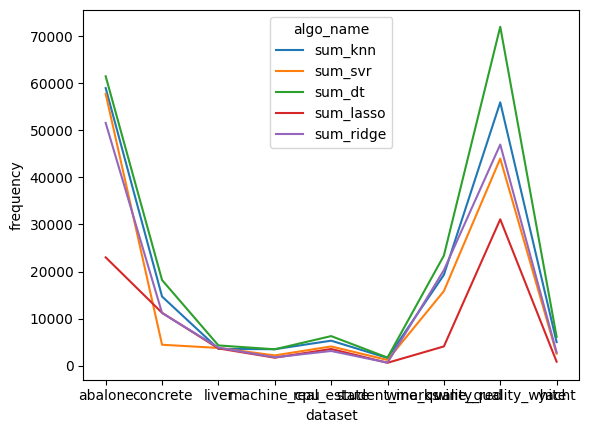

In [122]:

sns.lineplot(
    data=df_plot2,
    x='dataset',
    y='frequency',
    hue='algo_name',
    markers='o'
)

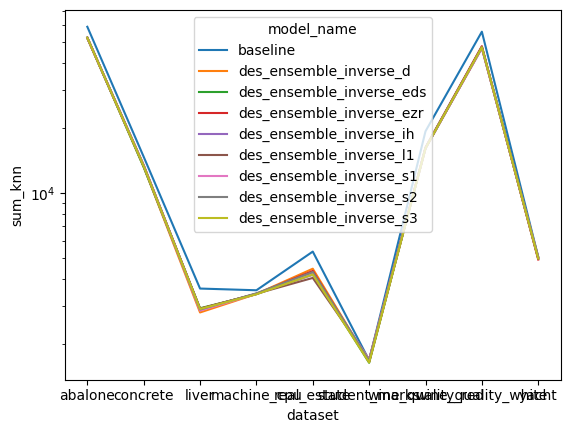

In [103]:

sns.lineplot(
    data=df_plot.query("model_name == 'baseline' or model_name.str.contains('inverse')"),
    x='dataset',
    y='sum_knn',
    hue='model_name',
    markers='x',
)
plt.yscale('log')

Prepare a 2D matrix or DataFrame:

- Rows: datasets/tasks.
- Columns: ML techniques/algorithms.
- Cells: performance metric (e.g., accuracy, F1 score).

In [82]:
des_friedman_df = \
    des_results\
    [[('mse', 'mean'), ('dataset', '')]]\
    .droplevel(1, axis=1)\
    .reset_index()\
    .replace(des_ensemble_latex_names)\
    .pivot_table(
        columns='model_name',
        index='dataset',
        values='mse'
    )
des_friedman_df

model_name,$DES$,$DES_{Degree_{IHM}}$,$DES_{EDS}$,$DES_{EZR}$,$DES_{IH}$,$DES_{LE}$,$DES_{S1}$,$DES_{S2}$,$DES_{S3}$,des_ensemble_inverse_d,des_ensemble_inverse_eds,des_ensemble_inverse_ezr,des_ensemble_inverse_ih,des_ensemble_inverse_l1,des_ensemble_inverse_s1,des_ensemble_inverse_s2,des_ensemble_inverse_s3
dataset,,,,,,,,,,,,,,,,,
abalone,4.7229,4.7044,4.7561,4.7420,4.7170,4.7390,4.6811,4.6967,4.7812,4.6994,4.6840,4.7001,4.6909,4.6844,4.6857,4.6973,4.6919
concrete,47.3514,37.0203,40.3502,40.8144,38.4127,39.3540,39.6268,37.2995,43.3802,38.8352,38.2529,37.9355,37.0559,37.4534,37.0577,37.7046,38.6296
liver,12.3692,12.5489,12.7185,12.7306,12.7957,12.7919,12.5494,12.5971,12.8388,12.5253,12.5157,12.5093,12.5157,12.5714,12.5935,12.5883,12.5163
machine_cpu,3396.8046,3434.3710,3717.5594,4045.0431,3424.6547,3373.6312,3564.3002,3287.1097,3969.7087,3252.2441,3267.4043,3252.1657,3275.6611,3257.2380,3244.0348,3114.3606,3266.0960
real_estate,45.1026,47.8673,46.0279,45.3471,48.2839,48.9946,48.3251,49.0158,47.2569,47.6024,45.4133,45.0315,47.0020,47.3989,47.8919,44.3994,45.6387
student_marks,2.3476,1.7898,1.9702,2.0112,1.8270,1.8284,1.8526,1.7737,2.1125,1.8278,1.8555,1.8274,1.7946,1.7900,1.7981,1.8448,1.8288
wine_quality_red,0.3952,0.3734,0.3758,0.3727,0.3718,0.3740,0.3701,0.3697,0.3817,0.3697,0.3716,0.3755,0.3700,0.3706,0.3699,0.3718,0.3715
wine_quality_white,0.4586,0.4407,0.4380,0.4456,0.4319,0.4347,0.4316,0.4300,0.4439,0.4295,0.4325,0.4325,0.4285,0.4307,0.4289,0.4288,0.4329
yacht,40.6294,26.3645,28.4893,37.5655,27.6015,26.5614,27.9890,26.3888,37.7951,27.3684,30.3625,26.9217,25.5881,26.2879,26.5148,179.2646,24.4225


In [83]:
from autorank import autorank, plot_stats, create_report, latex_table

des_friedman_result = autorank(des_friedman_df, alpha=0.05, verbose=False, order='ascending')

                           meanrank   median      mad ci_lower   ci_upper  \
des_ensemble_inverse_ih    4.166667  12.5157  12.1457     0.37  3275.6611   
des_ensemble_inverse_s1    5.555556  12.5935  12.2236   0.3699  3244.0348   
des_ensemble_inverse_l1    5.555556  12.5714  12.2008   0.3706   3257.238   
$DES_{S2}$                 6.833333  12.5971  12.2274   0.3697  3287.1097   
des_ensemble_inverse_s3    6.888889  12.5163  12.0834   0.3715   3266.096   
des_ensemble_inverse_ezr   6.944444  12.5093  12.1338   0.3755  3252.1657   
des_ensemble_inverse_d     7.055556  12.5253  12.1556   0.3697  3252.2441   
des_ensemble_inverse_s2    7.277778  12.5883  12.2165   0.3718  3114.3606   
des_ensemble_inverse_eds   7.666667  12.5157  12.1441   0.3716  3267.4043   
$DES_{Degree_{IHM}}$       8.444444  12.5489  12.1755   0.3734   3434.371   
$DES_{S1}$                 9.555556  12.5494  12.1793   0.3701  3564.3002   
$DES_{IH}$                10.722222  12.7957  12.4239   0.3718  3424.6547   

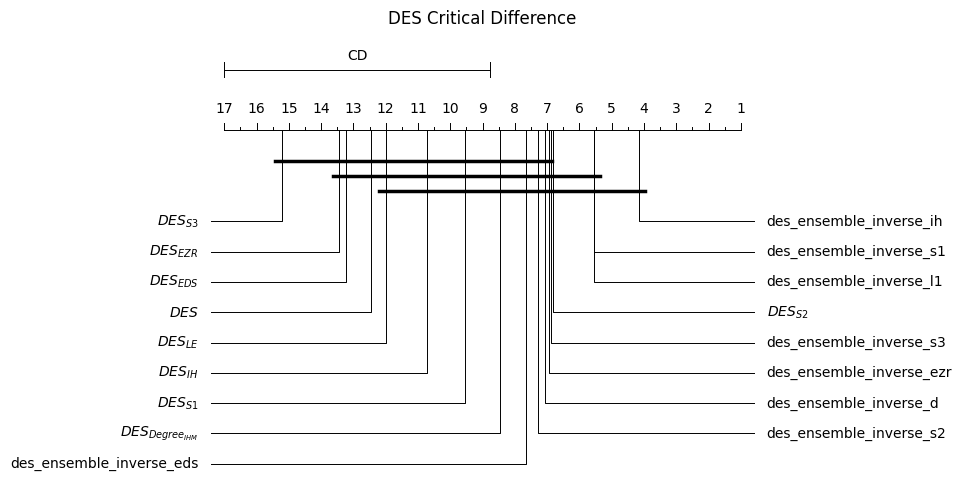

In [84]:
# Create a new figure
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(1, 1, 1)

# Plot the results
plot_stats(des_friedman_result, ax=ax)
plt.title("DES Critical Difference")
fig.savefig("img/des_friedman_cd_result.png")

# plot_stats(des_friedman_result, ax=ax)

In [88]:
friedman_values = des_friedman_df.values

In [89]:
from scipy.stats import friedmanchisquare

stat, p = friedmanchisquare(*[friedman_values[:, i] for i in range(friedman_values.shape[1])])

print(f"Friedman statistic: {stat:.4f}, p-value: {p:.4f}")
print(f"If p-value < 0.05, at least one algorithm differs")

Friedman statistic: 59.9390, p-value: 0.0000
If p-value < 0.05, at least one algorithm differs


In [90]:
import scikit_posthocs as sp

nemenyi = sp.posthoc_nemenyi_friedman(friedman_values)
pd.DataFrame(nemenyi)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,1.000000,0.962394,1.000000,1.000000,0.999999,1.000000,0.998815,0.611541,0.999264,0.681542,0.845622,0.646937,0.047041,0.236780,0.236780,0.747211,0.629319
1,0.962394,1.000000,0.845622,0.792328,0.999943,0.987930,1.000000,1.000000,0.262765,1.000000,1.000000,1.000000,0.932895,0.998815,0.998815,1.000000,1.000000
2,1.000000,0.845622,1.000000,1.000000,0.999805,1.000000,0.983530,0.366479,0.999990,0.433260,0.629319,0.399307,0.015131,0.102614,0.102614,0.503659,0.382741
3,1.000000,0.792328,1.000000,1.000000,0.999427,1.000000,0.970956,0.304889,0.999998,0.366479,0.557633,0.334957,0.010649,0.078202,0.078202,0.433260,0.319733
4,0.999999,0.999943,0.999805,0.999427,1.000000,1.000000,1.000000,0.970956,0.899798,0.983530,0.997702,0.977937,0.319733,0.747211,0.747211,0.991326,0.974632
5,1.000000,0.987930,1.000000,1.000000,1.000000,1.000000,0.999855,0.747211,0.995796,0.806430,0.925454,0.777742,0.083807,0.350544,0.350544,0.857596,0.762694
6,0.998815,1.000000,0.983530,0.970956,1.000000,0.999855,1.000000,0.999427,0.593642,0.999805,0.999996,0.999660,0.681542,0.962394,0.962394,0.999943,0.999557
7,0.611541,1.000000,0.366479,0.304889,0.970956,0.747211,0.999427,1.000000,0.040382,1.000000,1.000000,1.000000,0.999557,1.000000,1.000000,1.000000,1.000000
8,0.999264,0.262765,0.999990,0.999998,0.899798,0.995796,0.593642,0.040382,1.000000,0.054620,0.116924,0.047041,0.000433,0.005603,0.005603,0.072909,0.043602
9,0.681542,1.000000,0.433260,0.366479,0.983530,0.806430,0.999805,1.000000,0.054620,1.000000,1.000000,1.000000,0.998815,1.000000,1.000000,1.000000,1.000000


## DRS Results

In [143]:
drs_results = pd.concat([
    drs_abalone_agg_results.assign(dataset="abalone"),
    drs_student_marks_agg_results.assign(dataset="student_marks"),
    drs_concrete_agg_results.assign(dataset="concrete"),
    drs_liver_agg_results.assign(dataset="liver"),
    drs_machine_cpu_agg_results.assign(dataset="machine_cpu"),
    drs_wine_quality_red_agg_results.assign(dataset="wine_quality_red"),
    drs_wine_quality_white_agg_results.assign(dataset="wine_quality_white"),
    drs_real_estate_agg_results.assign(dataset="real_estate"),
    drs_yacht_agg_results.assign(dataset="yacht")
])


drs_results.drop(columns=[('mse', 'std')]).droplevel(1,axis=1)\
    .pivot_table(
        index=['model_name'],
        columns=['dataset'],
        values=[('mse')]
    )\
    .reset_index()\
    .replace(drs_ensemble_latex_names)

model_name     mse                                \
dataset                       abalone concrete    liver machine_cpu   
0                       $DRS$  5.7580  56.2360  16.3824   5307.0912   
1        $DRS_{Degree_{IHM}}$  9.2987  48.8697  21.9961   7432.8170   
2                 $DRS_{EDS}$  9.1994  49.4288  22.3026   7312.2663   
3                 $DRS_{EZR}$  9.1697  49.0732  21.9506   7329.9433   
4                  $DRS_{IH}$  9.2546  49.5254  23.6345   7421.9256   
5                  $DRS_{LE}$  9.3001  48.8034  22.8888   7209.6456   
6                  $DRS_{S1}$  9.3200  48.8783  22.2649   7391.0813   
7                  $DRS_{S2}$  9.4304  50.6979  23.6120   7408.9611   
8                  $DRS_{S3}$  9.3474  48.7828  22.3128   7729.7116   

                                                                                
dataset real_estate student_marks wine_quality_red wine_quality_white    yacht  
0           53.5001        3.9444           0.5956             0.6313  54.4884  
1          105.0404        4.5125           0.6581             0.7678   2.0456  
2          103.7879        4.3445           0.6581             0.7678   2.0407  
3          105.6531        4.6648           0.6395             0.7785   2.0407  
4          106.1463        4.5125           0.6581             0.7678   2.0456  
5          106.2019        4.3205           0.6581             0.7686   2.0456  
6          105.0252        4.4436           0.6606             0.7678   2.0456  
7          105.3950        4.4581           0.6606             0.7675   2.0456  
8          108.3291        4.5272           0.6572             0.7814   2.0405

In [149]:
drs_results.drop(columns=[('mse', 'std')]).droplevel(1,axis=1)\
    .pivot_table(
        index=['model_name'],
        columns=['dataset'],
        values=[('mse')]
    )\
    .reset_index()\
    .replace(drs_ensemble_latex_names)\
    .droplevel(0, axis=1).T.to_clipboard()

In [128]:
drs_friedman_df = \
    drs_results\
    [[('mse', 'mean'), ('dataset', '')]]\
    .droplevel(1, axis=1)\
    .reset_index()\
    .replace(drs_ensemble_latex_names)\
    .pivot_table(
        columns='model_name',
        index='dataset',
        values='mse'
    )
drs_friedman_df

NameError: name 'drs_results' is not defined

In [278]:
drs_friedman_result = autorank(drs_friedman_df, alpha=0.05, verbose=False, order='ascending')

                      meanrank   median      mad  ...   magnitude  \
$DRS$                 2.777778  16.3824  15.7868  ...  negligible   
$DRS_{EDS}$           3.833333   9.1994   8.5413  ...       small   
$DRS_{EZR}$           4.500000   9.1697   8.5302  ...       small   
$DRS_{Degree_{IHM}}$  5.055556   9.2987   8.6406  ...       small   
$DRS_{LE}$            5.055556   9.3001    8.642  ...       small   
$DRS_{S1}$            5.111111   9.3200   8.6594  ...       small   
$DRS_{S3}$            6.000000   9.3474   8.6902  ...       small   
$DRS_{IH}$            6.277778   9.2546   8.5965  ...       small   
$DRS_{S2}$            6.388889   9.4304   8.7698  ...       small   

                     effect_size_above magnitude_above  
$DRS$                              0.0      negligible  
$DRS_{EDS}$                   0.381724           small  
$DRS_{EZR}$                   0.002347      negligible  
$DRS_{Degree_{IHM}}$         -0.010134      negligible  
$DRS_{LE}$              

Text(0.5, 1.0, 'DRS Critical Difference')

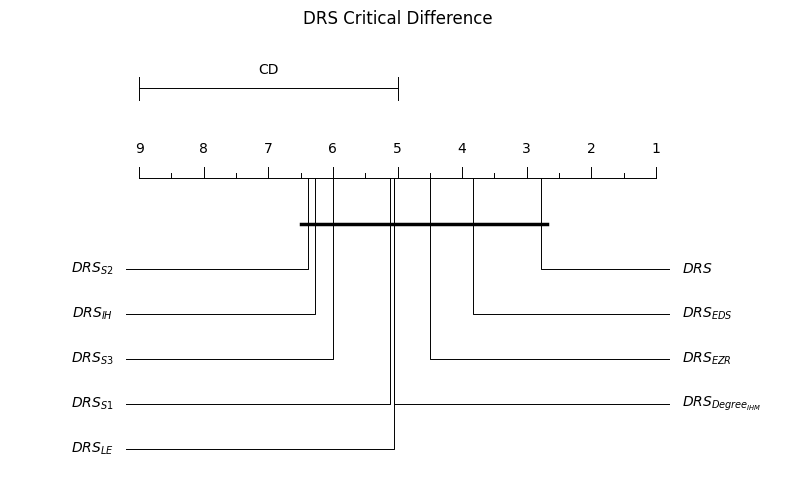

In [279]:
# Create a new figure
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(1, 1, 1)

# Plot the results
plot_stats(drs_friedman_result, ax=ax, allow_insignificant=True)
fig.savefig("img/drs_friedman_cd_result.png")
plt.title("DRS Critical Difference")

# plot_stats(des_friedman_result, ax=ax)

## Wilcoxon Test for DES

In [160]:
consolidated_meta_features_test.keys()

dict_keys(['abalone', 'concrete', 'liver', 'machineCPU', 'real_estate', 'student_marks', 'wine_quality_red', 'wine_quality_white', 'yacht'])

In [164]:
consolidated_meta_features_test['abalone'].shape

(4177, 52)

In [197]:
def repeat_meta_data_for_each_model(predictions_df, meta_data_df):
    list_df = list()
    variable_columns = [col for col in meta_data_df.columns if col.startswith('V')]
    for model_name in predictions_df['model_name'].unique():
        model_df = predictions_df.query("model_name == @model_name").reset_index(drop=True)
        tmp_df = pd.concat([
            model_df,
            meta_data_df.drop(columns=variable_columns)
        ], axis=1)
        list_df.append(tmp_df)
    all_data = pd.concat(list_df, ignore_index=True)
    return all_data

In [170]:
consolidated_meta_features_test['abalone']

,V0,V1,V2,V3,V4,V5,V6,V7,y,algo_ada_boost,algo_svr_linear,algo_svr_epsilon,algo_svr_nu,algo_decision_tree,algo_random_forest,algo_extra_tree,algo_gradient_boosting,algo_mlp,algo_bagging,algo_bayesian_ard,algo_kernel_ridge,algo_sgd,algo_passive_aggressive,algo_dummy_regressor,instance_hardness,inverse_instance_hardness,normalized_instance_hardness,normalized_inverse_instance_hardness,V0,V1,V2,V3,V4,V5,V6,V7,y,C4,CC,D,DS,EDS,EZR,FO,HB,L1,POT,S1,S2,S3,TD_P,TD_U
0,2,0.495,0.380,0.120,0.5730,0.2655,0.1285,0.1440,7,2.574803,1.330319,1.334835,1.642761,1.0,0.78,1.27,1.649433,1.562391,1.1,1.644805,8.319529,1.552574,2.169778,2.961999,0.178070,0.821930,0.223307,0.881952,2,0.495,0.380,0.120,0.5730,0.2655,0.1285,0.1440,7,1.000000,0.999300,0.446360,0.143550,0.017801,0.145943,0.000,0.906392,0.339855,0,0.007373,0.563621,0.106201,0.428571,0.428571
1,3,0.250,0.190,0.060,0.0765,0.0360,0.0115,0.0245,6,0.656716,0.613128,0.574288,0.919483,2.0,1.15,1.10,0.921676,1.042781,1.3,0.240757,10.077785,0.249367,0.263453,3.856929,0.130733,0.869267,0.163946,0.932745,3,0.250,0.190,0.060,0.0765,0.0360,0.0115,0.0245,6,0.333333,0.999655,0.775144,0.886518,0.131113,0.298794,0.000,0.937994,0.061819,0,0.001754,0.703311,0.106201,0.428571,0.464286
2,3,0.165,0.120,0.030,0.0215,0.0070,0.0050,0.0050,3,2.519802,1.166787,1.188188,1.091695,2.0,1.28,1.59,1.260553,0.673049,1.2,1.380166,8.540350,1.470658,1.857889,6.936845,0.188099,0.811901,0.235884,0.871191,3,0.165,0.120,0.030,0.0215,0.0070,0.0050,0.0050,3,1.000000,0.999681,0.844349,0.886518,0.700155,0.758241,0.375,0.996409,0.340543,1,0.002512,0.713380,0.075007,0.428571,0.357143
3,1,0.575,0.450,0.155,0.9480,0.4290,0.2060,0.2590,7,5.014085,3.235658,3.247611,2.914639,12.0,4.61,4.59,2.986757,2.833332,4.3,3.537535,6.416449,3.513010,4.519993,2.961999,0.350130,0.649870,0.439079,0.697327,1,0.575,0.450,0.155,0.9480,0.4290,0.2060,0.2590,7,1.000000,0.999344,0.483238,0.000000,0.634882,0.145943,0.000,0.906392,0.523323,0,0.007648,0.777913,0.267927,0.857143,0.500000
4,2,0.535,0.415,0.170,0.8790,0.2950,0.1965,0.2850,10,5.424544,1.514872,1.540969,2.702919,6.0,3.58,4.16,3.247283,3.660100,4.7,2.155610,7.718831,1.913356,2.868336,0.143071,0.272056,0.727944,0.341171,0.781102,2,0.535,0.415,0.170,0.8790,0.2950,0.1965,0.2850,10,0.777778,0.999178,0.402538,0.530553,0.076006,0.038672,0.000,0.848216,0.418931,0,0.012120,0.731698,0.593966,0.857143,0.607143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4172,2,0.460,0.360,0.115,0.4755,0.2105,0.1050,0.1600,8,2.182519,0.550562,0.558331,1.559938,1.0,2.12,2.17,2.271156,1.218826,4.2,0.955971,8.885066,1.114191,0.370953,1.856929,0.168727,0.831273,0.211591,0.891977,2,0.460,0.360,0.115,0.4755,0.2105,0.1050,0.1600,8,1.000000,0.999377,0.481082,0.143550,0.011351,0.038672,0.000,0.864017,0.235422,0,0.004342,0.587568,0.314336,0.428571,0.428571
4173,1,0.535,0.420,0.145,0.7910,0.3300,0.1890,0.2500,10,3.840257,0.326609,0.364198,0.822591,3.0,1.31,2.05,1.024202,0.225553,1.9,0.837724,9.113043,0.951314,3.043199,0.035607,0.159870,0.840130,0.200484,0.901481,1,0.535,0.420,0.145,0.7910,0.3300,0.1890,0.2500,10,0.888889,0.999364,0.497845,0.530553,0.076006,0.038672,0.000,0.848216,0.191211,0,0.007894,0.682065,0.000000,0.857143,0.535714
4174,3,0.380,0.275,0.110,0.2560,0.1100,0.0535,0.0755,6,2.488806,1.101319,1.135946,1.331505,1.0,1.72,2.85,1.272861,1.669790,2.7,1.416517,8.548612,1.480163,1.733938,3.964393,0.196373,0.803627,0.246260,0.862312,3,0.380,0.275,0.110,0.2560,0.1100,0.0535,0.0755,6,1.000000,0.999592,0.654454,0.806984,0.131113,0.298794,0.000,0.937994,0.305007,0,0.004766,0.615453,0.106201,0.571429,0.607143
4175,1,0.510,0.410,0.145,0.7960,0.3865,0.1815,0.1955,8,3.379435,0.947310,0.984313,0.779062,1.0,0.89,0.04,1.572910,0.566946,1.4,1.193050,8.764581,1.159652,2.741228,1.964393,0.154809,0.845191,0.194138,0.906911,1,0.510,0.410,0.145,0.7960,0.3865,0.1815,0.1955,8,1.000000,0.9

### Concatenate meta-features with test set

In [198]:
abalone_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_abalone_results_df.assign(dataset='abalone').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['abalone']
).reset_index(drop=True)

student_marks_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_student_marks_results_df.assign(dataset='student_marks').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['student_marks']
).reset_index(drop=True)

concrete_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_concrete_results_df.assign(dataset='concrete').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['concrete']
).reset_index(drop=True)

liver_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_liver_results_df.assign(dataset='liver').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['liver']
).reset_index(drop=True)

machine_cpu_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_machine_cpu_results_df.assign(dataset='machine_CPU').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['machineCPU']
).reset_index(drop=True)

wine_quality_red_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_wine_quality_red_results_df.assign(dataset='wine_quality_red').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['wine_quality_red']
).reset_index(drop=True)

wine_quality_white_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_wine_quality_white_results_df.assign(dataset='wine_quality_white').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['wine_quality_white']
).reset_index(drop=True)

real_estate_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_real_estate_results_df.assign(dataset='real_estate').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['real_estate']
).reset_index(drop=True)

yacht_des_all_data = repeat_meta_data_for_each_model(
    predictions_df=des_yacht_results_df.assign(dataset='yacht').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['yacht']
).reset_index(drop=True)

In [329]:
abalone_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_abalone_results_df.assign(dataset='abalone').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['abalone']
).reset_index(drop=True)

student_marks_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_student_marks_results_df.assign(dataset='student_marks').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['student_marks']
).reset_index(drop=True)

concrete_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_concrete_results_df.assign(dataset='concrete').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['concrete']
).reset_index(drop=True)

liver_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_liver_results_df.assign(dataset='liver').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['liver']
).reset_index(drop=True)

machine_cpu_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_machine_cpu_results_df.assign(dataset='machine_CPU').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['machineCPU']
).reset_index(drop=True)

wine_quality_red_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_wine_quality_red_results_df.assign(dataset='wine_quality_red').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['wine_quality_red']
).reset_index(drop=True)

wine_quality_white_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_wine_quality_white_results_df.assign(dataset='wine_quality_white').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['wine_quality_white']
).reset_index(drop=True)

real_estate_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_real_estate_results_df.assign(dataset='real_estate').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['real_estate']
).reset_index(drop=True)

yacht_drs_all_data = repeat_meta_data_for_each_model(
    predictions_df=drs_yacht_results_df.assign(dataset='yacht').explode(["y_true", "y_pred"]), 
    meta_data_df=consolidated_meta_features_test['yacht']
).reset_index(drop=True)

In [279]:
all_datasets_predictions = pd.concat([
    des_abalone_results_df.assign(dataset='abalone').explode(["y_true", "y_pred"]),
    des_student_marks_results_df.assign(dataset='student_marks').explode(["y_true", "y_pred"]),
    des_concrete_results_df.assign(dataset='concrete').explode(["y_true", "y_pred"]),
    des_liver_results_df.assign(dataset='liver').explode(["y_true", "y_pred"]),
    des_machine_cpu_results_df.assign(dataset='machine_CPU').explode(["y_true", "y_pred"]),
    des_wine_quality_red_results_df.assign(dataset='wine_quality_red').explode(["y_true", "y_pred"]),
    des_wine_quality_white_results_df.assign(dataset='wine_quality_white').explode(["y_true", "y_pred"]),
    des_real_estate_results_df.assign(dataset='real_estate').explode(["y_true", "y_pred"]),
    des_yacht_results_df.assign(dataset='yacht').explode(["y_true", "y_pred"]),
])

all_datasets_predictions.head()


,mse,r2,mae,rmse,mape,execution_time,y_pred,y_true,status,model_name,partition,dataset
0,4.929206,0.541049,1.533017,2.220181,0.150423,57.024892,8.112,7,success,baseline,1,abalone
0,4.929206,0.541049,1.533017,2.220181,0.150423,57.024892,5.381912,6,success,baseline,1,abalone
0,4.929206,0.541049,1.533017,2.220181,0.150423,57.024892,4.191431,3,success,baseline,1,abalone
0,4.929206,0.541049,1.533017,2.220181,0.150423,57.024892,10.785503,7,success,baseline,1,abalone
0,4.929206,0.541049,1.533017,2.220181,0.150423,57.024892,12.648472,10,success,baseline,1,abalone


In [206]:
all_datasets_des_all_data = pd.concat([
    abalone_des_all_data,
    student_marks_des_all_data,
    concrete_des_all_data,
    liver_des_all_data,
    machine_cpu_des_all_data,
    wine_quality_red_des_all_data,
    wine_quality_white_des_all_data,
    real_estate_des_all_data,
    yacht_des_all_data
], axis=0, ignore_index=True)\
    .assign(squared_error = lambda d: (d['y_true'] - d['y_pred'])**2)

ih_bucket_labels = [
    '0-0.1', 
    '0.1-0.2', 
    '0.2-0.3', 
    '0.3-0.4', 
    '0.4-0.5',
    '0.5-0.6', 
    '0.6-0.7', 
    '0.7-0.8', 
    '0.8-0.9', 
    '0.9-1.0'
]

all_datasets_des_all_data['ih_bin'] = pd.cut(
    all_datasets_des_all_data['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    labels=ih_bucket_labels, 
    include_lowest=True
).astype("str")

all_datasets_des_all_data.shape

(117729, 50)

In [362]:
all_datasets_drs_all_data = pd.concat([
    abalone_drs_all_data,
    student_marks_drs_all_data,
    concrete_drs_all_data,
    liver_drs_all_data,
    machine_cpu_drs_all_data,
    wine_quality_red_drs_all_data,
    wine_quality_white_drs_all_data,
    real_estate_drs_all_data,
    yacht_drs_all_data
], axis=0, ignore_index=True)\
    .assign(squared_error = lambda d: (d['y_true'] - d['y_pred'])**2)

ih_bucket_labels = [
    '0-0.1', 
    '0.1-0.2', 
    '0.2-0.3', 
    '0.3-0.4', 
    '0.4-0.5',
    '0.5-0.6', 
    '0.6-0.7', 
    '0.7-0.8', 
    '0.8-0.9', 
    '0.9-1.0'
]

all_datasets_drs_all_data['ih_bin'] = pd.cut(
    all_datasets_drs_all_data['instance_hardness'], 
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    labels=ih_bucket_labels, 
    include_lowest=True
).astype("str")

all_datasets_drs_all_data.shape

(117729, 50)

### MSE per IH (DES)

In [260]:
mse_per_instance_hardness = all_datasets_des_all_data\
    .groupby(["dataset", "model_name", "ih_bin"])\
    .agg(
        mse = ("squared_error", "mean")
    )\
    .reset_index()\
    .assign(latex_model_name = lambda d: d['model_name'].replace(des_ensemble_latex_names))

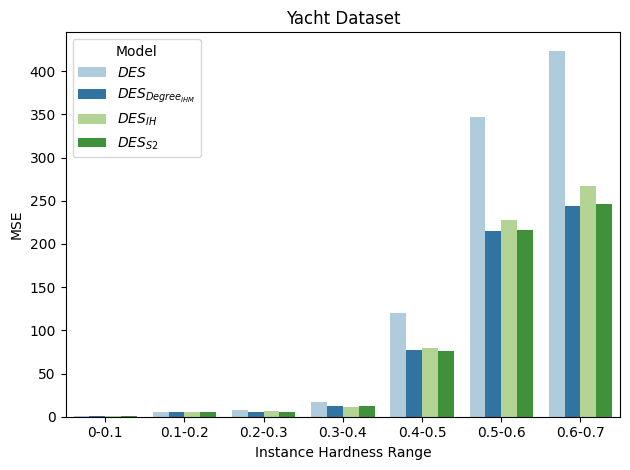

In [272]:
sns.barplot(
    data=mse_per_instance_hardness\
        .query("model_name in ['baseline', 'des_ensemble_d', 'des_ensemble_s2', 'des_ensemble_ih']")\
        .query("dataset == 'yacht'")
    , x='ih_bin'
    , y='mse'
    , hue='latex_model_name'
    , palette=sns.color_palette("Paired", 4)
)
plt.legend(title='Model')
plt.ylabel('MSE')
plt.xlabel('Instance Hardness Range')
plt.title('Yacht Dataset')
plt.tight_layout()
plt.savefig('img/yacht-mse-per-model.png', dpi=300)

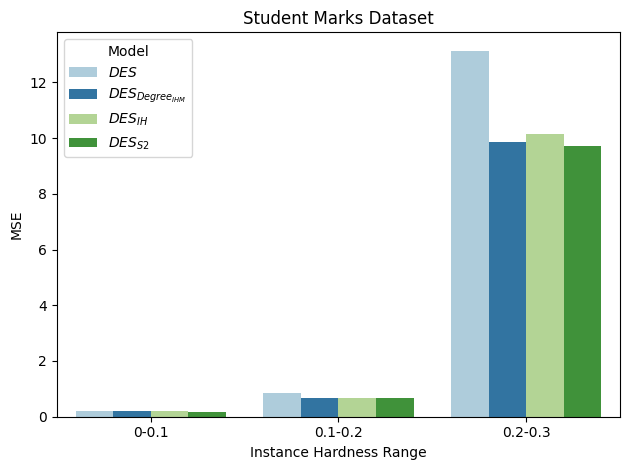

In [273]:
sns.barplot(
    data=mse_per_instance_hardness\
        .query("model_name in ['baseline', 'des_ensemble_d', 'des_ensemble_s2', 'des_ensemble_ih']")\
        .query("dataset == 'student_marks'")
    , x='ih_bin'
    , y='mse'
    , hue='latex_model_name'
    , palette=sns.color_palette("Paired", 4)
)
plt.legend(title='Model')
plt.ylabel('MSE')
plt.xlabel('Instance Hardness Range')
plt.title('Student Marks Dataset')
plt.tight_layout()
plt.savefig('img/student-marks-mse-per-model.png', dpi=300)

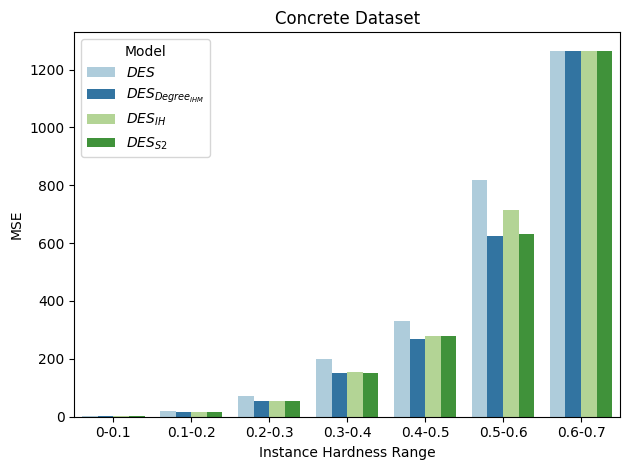

In [274]:
sns.barplot(
    data=mse_per_instance_hardness\
        .query("model_name in ['baseline', 'des_ensemble_d', 'des_ensemble_s2', 'des_ensemble_ih']")\
        .query("dataset == 'concrete'")
    , x='ih_bin'
    , y='mse'
    , hue='latex_model_name'
    , palette=sns.color_palette("Paired", 4)
)
plt.legend(title='Model')
plt.ylabel('MSE')
plt.xlabel('Instance Hardness Range')
plt.title('Concrete Dataset')
plt.tight_layout()
plt.savefig('img/concrete-mse-per-model.png', dpi=300)

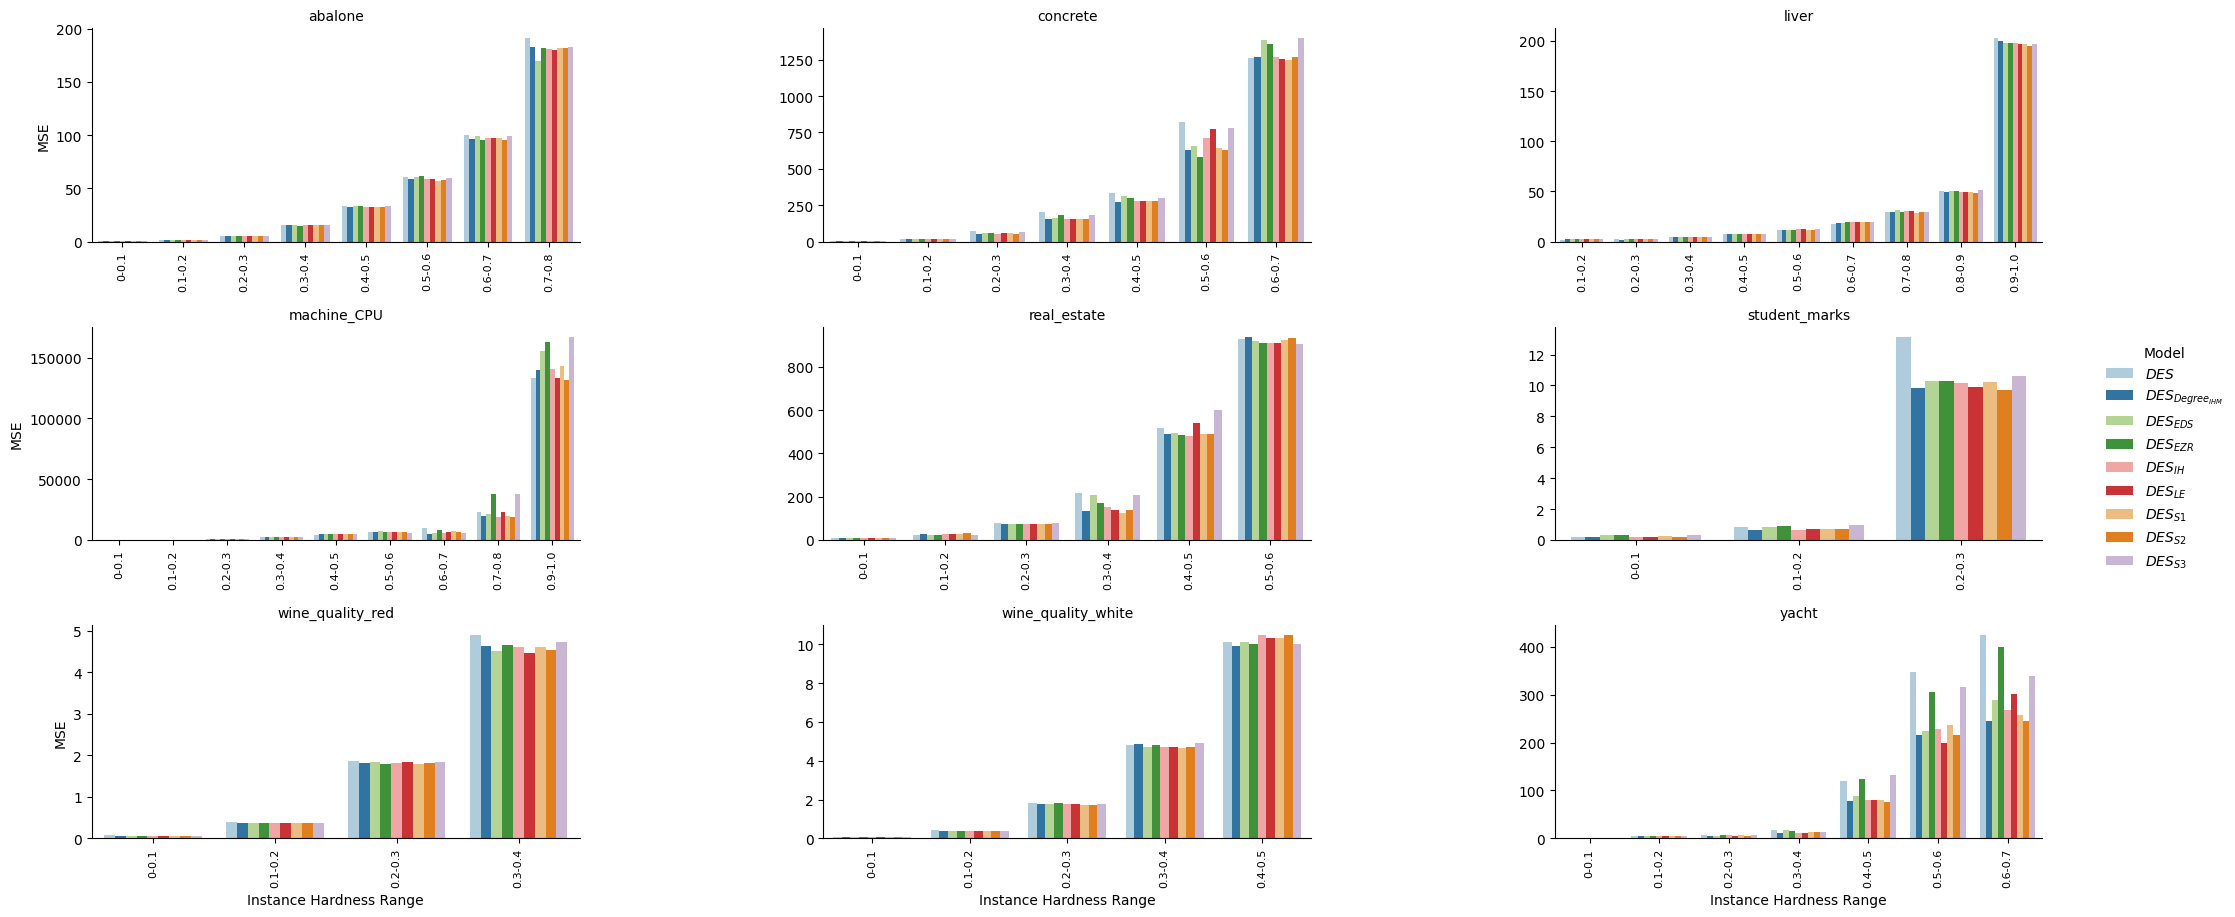

In [278]:
g = sns.FacetGrid(
    data = mse_per_instance_hardness,
    col = 'dataset',
    col_wrap = 3,
    sharex = False,
    sharey = False,
    height = 3,
    aspect = 2.5,
    legend_out=True,
)
g.map_dataframe(
    sns.barplot,
    x='ih_bin',
    y='mse',
    width=0.8,
    hue='latex_model_name',
    palette=sns.color_palette("Paired", 9),
)
g.set_xticklabels(rotation=90, fontsize=8)
g.set_xlabels('Instance Hardness Range')
g.set_ylabels('MSE')
g.add_legend(title='Model')
g.set_titles(template='{col_name}')
plt.subplots_adjust(
    left=0.1,
    bottom=0.1, 
    right=0.92,  # Increased from 0.8 to 0.9 to reduce space between plots and legend
    top=1.0, 
    wspace=0.5, 
    hspace=0.4
)
# Save figure
g.savefig('img/des-mse-per-model.png', dpi=300)

### MSE per IH (DRS)

In [363]:
drs_mse_per_instance_hardness = all_datasets_drs_all_data\
    .groupby(["dataset", "model_name", "ih_bin"])\
    .agg(
        mse = ("squared_error", "mean")
    )\
    .reset_index()\
    .assign(latex_model_name = lambda d: d['model_name'].replace(drs_ensemble_latex_names))

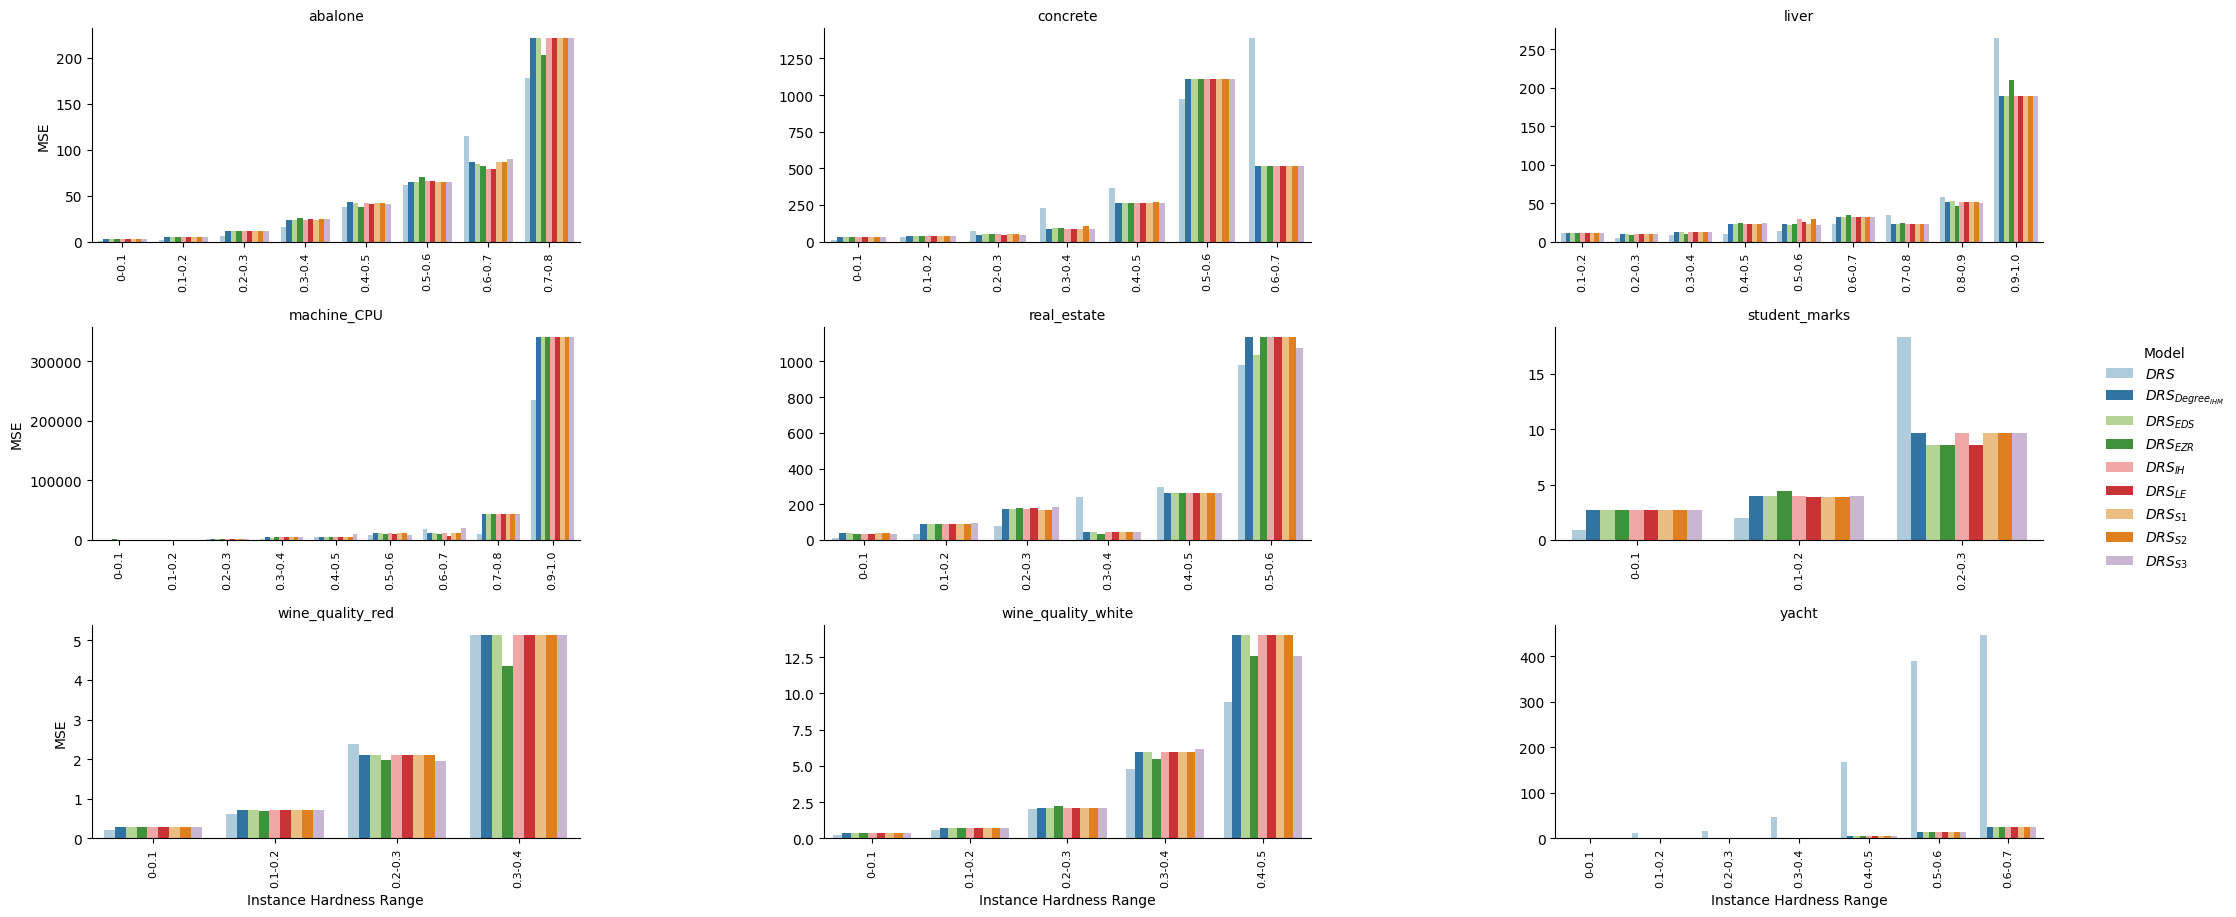

In [364]:
g = sns.FacetGrid(
    data = drs_mse_per_instance_hardness,
    col = 'dataset',
    col_wrap = 3,
    sharex = False,
    sharey = False,
    height = 3,
    aspect = 2.5,
    legend_out=True,
)
g.map_dataframe(
    sns.barplot,
    x='ih_bin',
    y='mse',
    width=0.8,
    hue='latex_model_name',
    palette=sns.color_palette("Paired", 9),
)
g.set_xticklabels(rotation=90, fontsize=8)
g.set_xlabels('Instance Hardness Range')
g.set_ylabels('MSE')
g.add_legend(title='Model')
g.set_titles(template='{col_name}')
plt.subplots_adjust(
    left=0.1,
    bottom=0.1, 
    right=0.92,  # Increased from 0.8 to 0.9 to reduce space between plots and legend
    top=1.0, 
    wspace=0.5, 
    hspace=0.4
)
# Save figure
g.savefig('img/drs-mse-per-model.png', dpi=300)

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_40443/3486941213.py:1: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


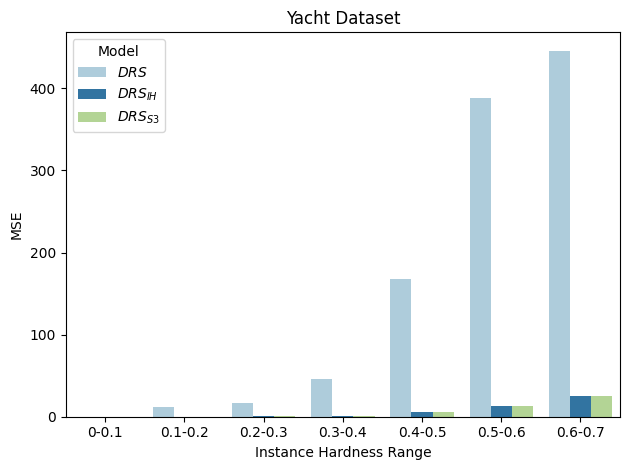

In [368]:
sns.barplot(
    data=drs_mse_per_instance_hardness\
        .query("model_name in ['baseline', 'drs_ensemble_s3', 'drs_ensemble_ih']")\
        .query("dataset == 'yacht'")
    , x='ih_bin'
    , y='mse'
    , hue='latex_model_name'
    , palette=sns.color_palette("Paired", 4)
)
plt.legend(title='Model')
plt.ylabel('MSE')
plt.xlabel('Instance Hardness Range')
plt.title('Yacht Dataset')
plt.tight_layout()
plt.savefig('img/yacht-drs-mse-per-model.png', dpi=300)

/var/folders/4y/1s_blnq50rq_v67_438xyd2m0000gp/T/ipykernel_40443/3729462263.py:1: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


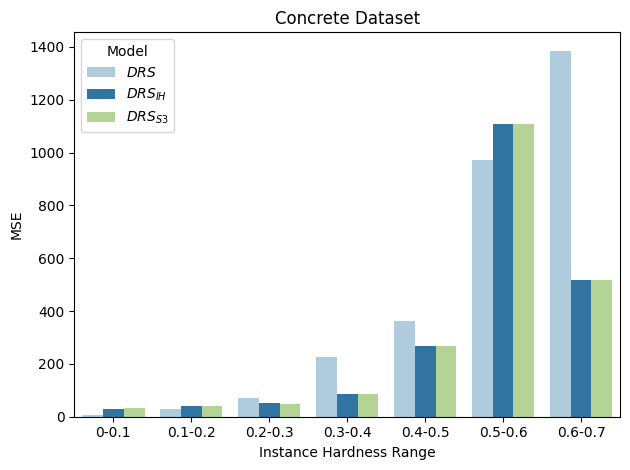

In [370]:
sns.barplot(
    data=drs_mse_per_instance_hardness\
        .query("model_name in ['baseline', 'drs_ensemble_s3', 'drs_ensemble_ih']")\
        .query("dataset == 'concrete'")
    , x='ih_bin'
    , y='mse'
    , hue='latex_model_name'
    , palette=sns.color_palette("Paired", 4)
)
plt.legend(title='Model')
plt.ylabel('MSE')
plt.xlabel('Instance Hardness Range')
plt.title('Concrete Dataset')
plt.tight_layout()
plt.savefig('img/concrete-drs-mse-per-model.png', dpi=300)

In [64]:
def get_model_mse_results(model_name, results_df):
    return results_df\
        [[('mse', 'mean'), ('dataset', '')]]\
        .droplevel(1, axis=1)\
        .reset_index()\
        .query("model_name == @model_name")\
        ['mse'].values

def get_model_predictions(model_name, results_df):
    return results_df\
        [[('mse', 'mean'), ('dataset', '')]]\
        .droplevel(1, axis=1)\
        .reset_index()\
        .query("model_name == @model_name")\
        ['mse'].values


In [117]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

pivoted = all_datasets_predictions.pivot_table(index=['dataset'], columns=['model_name'], values='y_pred', aggfunc=list)
results = {}

des_s2_predictions_wilcoxon_results = {}
for dataset, row in pivoted.iterrows():
    preds_a = row.get('baseline')
    preds_b = row.get('des_ensemble_s2')

    stat, p = wilcoxon(preds_a, preds_b, alternative='two-sided')
    results[dataset] = {'statistic': stat, 'p-value': p}

results_df = pd.DataFrame(results).T.round(4)

# Apply Holm correction
rejected, pvals_corrected, _, _ = multipletests(results_df['p-value'], alpha=0.05, method='holm')
results_df['p-corrected'] = pvals_corrected
results_df['reject_null'] = rejected
results_df

,statistic,p-value,p-corrected,reject_null
abalone,3331055.0,0.0000,0.0000,True
concrete,215640.0,0.0001,0.0008,True
liver,23063.0,0.0003,0.0021,True
machine_CPU,7695.0,0.0011,0.0066,True
real_estate,42051.0,0.9746,1.0000,False
student_marks,2014.0,0.3235,1.0000,False
wine_quality_red,610881.0,0.2394,1.0000,False
wine_quality_white,5860281.5,0.8251,1.0000,False
yacht,18245.0,0.4507,1.0000,False


In [120]:
results_df.drop(columns=['p-value', 'statistic']).to_clipboard()

In [58]:
baseline_yacht_predictions = des_yacht_results_df\
    .explode(["y_true", "y_pred"])\
    .astype({"y_pred": "float64"})\
    .query("model_name == 'baseline'")

des_s2_yacht_predictions = des_yacht_results_df\
    .explode(["y_true", "y_pred"])\
    .astype({"y_pred": "float64"})\
    .query("model_name == 'des_ensemble_d'")

In [ ]:

# plot baseline and des_s2 predictions
sns.kdeplot(baseline_yacht_predictions['y_pred'], label='Baseline')
sns.kdeplot(des_s2_yacht_predictions['y_pred'], label=r'$DES_{S2}$')
plt.legend()
plt.show()

In [93]:
baseline_yacht_predictions.head()

,mse,r2,mae,rmse,mape,execution_time,y_pred,y_true,status,model_name,partition
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.330613,1.296429,0.11,success,baseline,1
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.330613,1.259244,0.27,success,baseline,1
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.330613,1.481672,0.47,success,baseline,1
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.330613,1.726464,0.78,success,baseline,1
0,32.184393,0.83783,3.231343,5.673129,2.461356,2.330613,2.043427,1.18,success,baseline,1


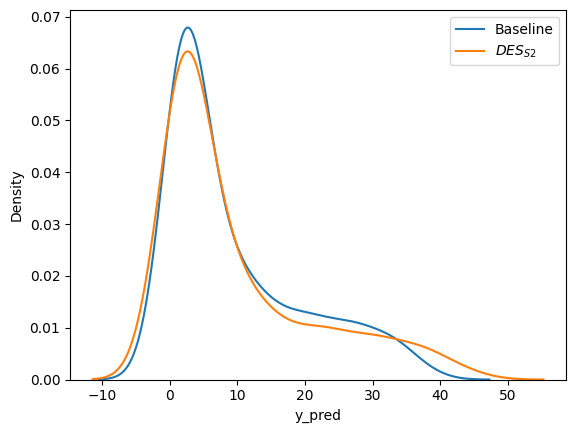

In [92]:
# plot baseline and des_s2 predictions
sns.kdeplot(baseline_yacht_predictions['y_pred'], label='Baseline')
sns.kdeplot(des_s2_yacht_predictions['y_pred'], label=r'$DES_{S2}$')
plt.legend()
plt.show()

In [60]:
from scipy.stats import wilcoxon

# Run two-sided Wilcoxon signed-rank test
stat, p_value = wilcoxon(
    baseline_yacht_predictions['y_pred'].to_numpy(), 
    des_s2_yacht_predictions['y_pred'].to_numpy(), 
    alternative='two-sided'
)

print(f"Wilcoxon statistic: {stat}")
print(f"P-value: {p_value:.4f}")

# Optional interpretation
alpha = 0.05
if p_value < alpha:
    print("Significant difference between Model A and B.")
else:
    print("No significant difference between Model A and B.")

Wilcoxon statistic: 18238.0
P-value: 0.3903
No significant difference between Model A and B.


In [62]:
des_results

mse              r2             mae            rmse  \
                     mean     std    mean     std    mean     std    mean   
model_name                                                                  
baseline           4.7228  0.4447  0.5454  0.0087  1.5065  0.0563  2.1713   
des_ensemble_d     4.7045  0.3892  0.5469  0.0049  1.5120  0.0534  2.1675   
des_ensemble_eds   4.7561  0.5100  0.5426  0.0103  1.5153  0.0648  2.1784   
des_ensemble_ezr   4.7421  0.3833  0.5432  0.0081  1.5165  0.0441  2.1762   
des_ensemble_ih    4.7275  0.4174  0.5448  0.0046  1.5134  0.0580  2.1726   
...                   ...     ...     ...     ...     ...     ...     ...   
des_ensemble_ih   27.7758  7.4612  0.8789  0.0224  2.9818  0.3240  5.2350   
des_ensemble_l1   26.6500  4.1889  0.8824  0.0160  2.8810  0.3866  5.1499   
des_ensemble_s1   28.0807  8.7638  0.8790  0.0253  2.9792  0.4596  5.2417   
des_ensemble_s2   26.4777  7.0794  0.8852  0.0194  2.9163  0.3430  5.1056   
des_ensemble_s3   37.8793  4.7791  0.8310  0.0326  3.4405  0.3894  6.1444   

                            mape         execution_time                    \
                     std    mean     std           mean     std       sum   
model_name                                                                  
baseline          0.1018  0.1479  0.0040        53.2371  2.1408  266.1853   
des_ensemble_d    0.0892  0.1491  0.0044        49.2334  0.4523  246.1669   
des_ensemble_eds  0.1159  0.1493  0.0049        49.3129  0.4481  246.5645   
des_ensemble_ezr  0.0877  0.1496  0.0031        48.8393  0.2313  244.1963   
des_ensemble_ih   0.0953  0.1491  0.0047        61.1048  0.6181  305.5239   
...                  ...     ...     ...            ...     ...       ...   
des_ensemble_ih   0.6808  2.1083  1.1680         3.8515  0.5872   19.2574   
des_ensemble_l1   0.4010  1.9884  0.8932         2.1145  0.0523   10.5725   
des_ensemble_s1   0.8698  2.1014  1.2310         2.1217  0.0242   10.6084   
des_ensemble_s2   0.7160  2.1754  1.2328         2.1331  0.0831   10.6653   
des_ensemble_s3   0.3971  1.7976  0.8960         2.1907  0.1062   10.9535   

                  dataset  
                           
model_name                 
baseline          abalone  
des_ensemble_d    abalone  
des_ensemble_eds  abalone  
des_ensemble_ezr  abalone  
des_ensemble_ih   abalone  
...                   ...  
des_ensemble_ih     yacht  
des_ensemble_l1     yacht  
des_ensemble_s1     yacht  
des_ensemble_s2     yacht  
des_ensemble_s3     yacht  

[81 rows x 14 columns]

In [76]:
des_s1_mse_scores = get_model_mse_results('des_ensemble_s1', des_results)
des_s2_mse_scores = get_model_mse_results('des_ensemble_s2', des_results)
des_s3_mse_scores = get_model_mse_results('des_ensemble_s3', des_results)
des_degree_mse_scores = get_model_mse_results('des_ensemble_d', des_results)

des_baseline_mse_scores = get_model_mse_results('baseline', des_results)

In [125]:
from scipy.stats import wilcoxon

# Run two-sided Wilcoxon signed-rank test
stat, p_value = wilcoxon(des_s2_mse_scores, des_baseline_mse_scores, alternative='less')

print(f"Wilcoxon statistic: {stat}")
print(f"P-value: {p_value:.4f}")

# Optional interpretation
alpha = 0.05
if p_value < alpha:
    print("Significant difference between Model A and B.")
else:
    print("No significant difference between Model A and B.")

Wilcoxon statistic: 10.0
P-value: 0.0820
No significant difference between Model A and B.


In [72]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

p1 = wilcoxon(des_baseline_mse_scores, des_s2_mse_scores).pvalue
p2 = wilcoxon(des_baseline_mse_scores, des_degree_mse_scores).pvalue
p3 = wilcoxon(des_s2_mse_scores, des_degree_mse_scores).pvalue

pvals = [p1, p2, p3]
reject, pvals_corrected, _, _ = multipletests(pvals, method='bonferroni')

for i, (rej, p_corr) in enumerate(zip(reject, pvals_corrected)):
    print(f"Comparison {i+1}: corrected p = {p_corr:.4f} → {'Significant' if rej else 'Not significant'}")

Comparison 1: corrected p = 0.4922 → Not significant
Comparison 2: corrected p = 1.0000 → Not significant
Comparison 3: corrected p = 1.0000 → Not significant


## Wilcoxon for DRS results

In [150]:
drs_s3_mse_scores = get_model_mse_results('drs_ensemble_s3', drs_results)
drs_baseline_mse_scores = get_model_mse_results('baseline', drs_results)

In [151]:
from scipy.stats import wilcoxon

# Run two-sided Wilcoxon signed-rank test
stat, p_value = wilcoxon(drs_s3_mse_scores, drs_baseline_mse_scores, alternative='less')

print(f"Wilcoxon statistic: {stat}")
print(f"P-value: {p_value:.4f}")

# Optional interpretation
alpha = 0.05
if p_value < alpha:
    print("Significant difference between Model A and B.")
else:
    print("No significant difference between Model A and B.")

Wilcoxon statistic: 32.0
P-value: 0.8750
No significant difference between Model A and B.


## SE Results

In [125]:
se_results = pd.concat([
    se_abalone_agg_results.assign(dataset="abalone"),
    se_student_marks_agg_results.assign(dataset="student_marks"),
    se_concrete_agg_results.assign(dataset="concrete"),
    se_liver_agg_results.assign(dataset="liver"),
    se_machine_cpu_agg_results.assign(dataset="machine_cpu"),
    se_wine_quality_red_agg_results.assign(dataset="wine_quality_red"),
    se_wine_quality_white_agg_results.assign(dataset="wine_quality_white"),
    se_real_estate_agg_results.assign(dataset="real_estate"),
    se_yacht_agg_results.assign(dataset="yacht")
])


se_results.drop(columns=[('mse', 'std')]).droplevel(1,axis=1)\
    .pivot_table(
        index=['model_name'],
        columns=['dataset'],
        values=[('mse')]
    )\
    .reset_index()\
    .replace(se_ensemble_latex_names)

model_name     mse                                \
dataset                       abalone concrete    liver machine_cpu   
0                        $SE$  4.9603  73.6934  12.0564   5366.1399   
1        se_baseline_ensemble  4.9603  73.6934  12.0564   5366.1399   
2                   $SE_{IH}$  4.9603  73.6934  12.0564   5366.1399   

                                                                                
dataset real_estate student_marks wine_quality_red wine_quality_white    yacht  
0           51.1237        5.7327           0.4251             0.5169  86.7589  
1           51.1237        5.7327           0.4251             0.5169  86.7589  
2           51.1237        5.7327           0.4251             0.5169  86.7589